Loaded 128,160 rows | 2026-01-01 00:00:00+00:00 → 2026-03-30 23:59:00+00:00
Missing values per chain:
avalanche_c    0
bnb            0
ethereum       0
optimism       0
After dropping missing rows: 128,160 rows | 2026-01-01 00:00:00+00:00 → 2026-03-30 23:59:00+00:00
Period length: 89.00 days

── Step 1: Deviation Statistics (%) ─────────────────────────────
                           Mean  Median (P50)     P90     P95     P99     Max     Std
Series                                                                               
Global (max-min)/median  0.1982        0.1677  0.3759  0.4347  0.5534  4.3966  0.1319
|Avalanche - median|     0.0304        0.0215  0.0675  0.0859  0.1487  1.2587  0.0327
|BNB Chain - median|     0.0314        0.0226  0.0699  0.0894  0.1437  2.4065  0.0333
|Ethereum - median|      0.1397        0.1101  0.3155  0.3705  0.4689  4.2829  0.1249
|Optimism - median|      0.0334        0.0244  0.0757  0.0953  0.1329  2.2904  0.0330
Saved: step1_statistics.csv

False re

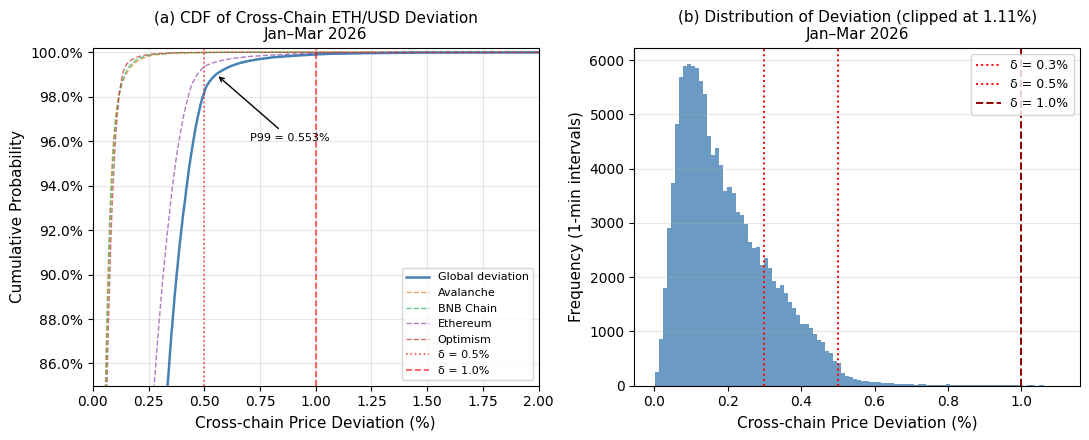

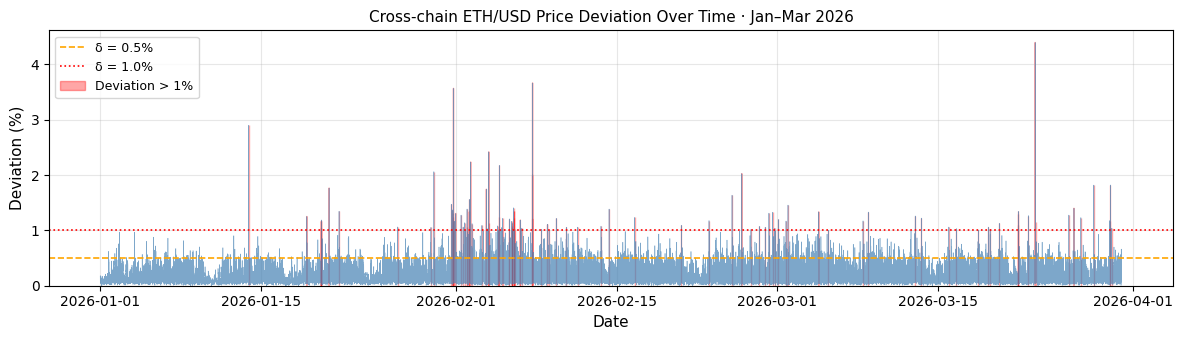

In [ ]:
"""
Master Evaluation Notebook — Step 1/6
Step 1: Cross-chain price deviation distribution

Run this notebook from the pub-repo/notebooks folder.
Only change the CONFIG block below for a different asset/time period.
"""

import json
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── CONFIG ───────────────────────────────────────────────────────────────────
DATASET_NAME = "ETH/USD 2026"       # used in printed summaries
ASSET_LABEL = "ETH/USD"             # used in figure titles
PERIOD_LABEL = "Jan–Mar 2026"       # used in figure titles
CSV_PATH = "../dataset/eth-janmar26/1min.csv"
OUTPUT_DIR = Path(".")
SEED = 42

CHAINS = ["avalanche_c", "bnb", "ethereum", "optimism"]
CHAIN_LABELS = {
    "avalanche_c": "Avalanche",
    "bnb":         "BNB Chain",
    "ethereum":    "Ethereum",
    "optimism":    "Optimism",
}

# Main protocol / experiment parameters. These are experimental choices, not
# derived results from earlier steps.
DELTA = 0.005
EPSILON_VALUES = [1.10, 1.25, 1.50]
C_TOTAL_VALUES = [10, 50, 100, 500]
Y_VALUES = [10_000, 100_000, 500_000, 1_000_000]
REP_C_TOTAL = 50
REP_EXPOSURE = 100_000
RAMP_STEPS = 5
N_ATTACKS = 500
N_RUNS = 100
CONTAMINATION = 0.15
COOLDOWN_MINS = 15

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
RESULTS = {}

# ── Load once and share across all steps ──────────────────────────────────────
df_raw = pd.read_csv(CSV_PATH, parse_dates=["block_time"])
df_raw = df_raw.set_index("block_time").sort_index()

print(f"Loaded {len(df_raw):,} rows | {df_raw.index.min()} → {df_raw.index.max()}")
print("Missing values per chain:")
print(df_raw[CHAINS].isna().sum().to_string())

df = df_raw.dropna(subset=CHAINS).copy()
prices = df[CHAINS]
row_max = prices.max(axis=1)
row_min = prices.min(axis=1)
row_med = prices.median(axis=1)

TOTAL_MINS = len(df)
TOTAL_HOURS = TOTAL_MINS / 60
TOTAL_DAYS = TOTAL_MINS / 60 / 24
OBS_START = df.index.min()
OBS_END = df.index.max() + pd.Timedelta(minutes=1)

print(f"After dropping missing rows: {len(df):,} rows | {OBS_START} → {df.index.max()}")
print(f"Period length: {TOTAL_DAYS:.2f} days\n")

# ── Shared helpers ───────────────────────────────────────────────────────────
def effective_suspension_minutes(violation_series, cooldown_mins):
    """Merge overlapping xOCB cooldown windows and return effective minutes."""
    active_times = violation_series.index[violation_series.to_numpy()]
    if len(active_times) == 0:
        return 0.0, []
    cooldown = pd.Timedelta(minutes=cooldown_mins)
    intervals = []
    for t in active_times:
        start = max(t, OBS_START)
        end = min(t + cooldown, OBS_END)
        if end > start:
            intervals.append((start, end))
    if not intervals:
        return 0.0, []
    intervals.sort(key=lambda x: x[0])
    merged = []
    cur_start, cur_end = intervals[0]
    for start, end in intervals[1:]:
        if start <= cur_end:
            cur_end = max(cur_end, end)
        else:
            merged.append((cur_start, cur_end))
            cur_start, cur_end = start, end
    merged.append((cur_start, cur_end))
    total_mins = sum((end - start).total_seconds() / 60.0 for start, end in merged)
    return total_mins, merged


def build_injected_prices(base_prices, attacked_chain=None, partial_theta=1.0):
    injected = {}
    for c in CHAINS:
        if attacked_chain is None:
            value = base_prices[c]
        elif c == attacked_chain:
            value = base_prices[c] * partial_theta
        else:
            value = base_prices[c] * (1.0 + (partial_theta - 1.0) * CONTAMINATION)
        injected[c] = value
    return injected


def xtcp_x1(noisy_prices, checked_chain, delta):
    median_p = np.median([noisy_prices[c] for c in CHAINS])
    deviation = abs(noisy_prices[checked_chain] - median_p) / median_p
    return deviation > delta


def apply_x2(candidate_price, last_accepted_price, epsilon):
    if last_accepted_price is None:
        return candidate_price, False
    max_allowed = last_accepted_price * epsilon
    if candidate_price > max_allowed:
        return max_allowed, True
    return candidate_price, False


def print_latex(lines):
    print("\n".join(lines))

# ── Step 1 calculations ──────────────────────────────────────────────────────
df["global_deviation_pct"] = (row_max - row_min) / row_med * 100
for c in CHAINS:
    df[f"dev_{c}"] = ((df[c] - row_med) / row_med * 100).abs()


def summary(series, label):
    return {
        "Series":       label,
        "Mean":         round(series.mean(), 4),
        "Median (P50)": round(series.median(), 4),
        "P90":          round(series.quantile(0.90), 4),
        "P95":          round(series.quantile(0.95), 4),
        "P99":          round(series.quantile(0.99), 4),
        "Max":          round(series.max(), 4),
        "Std":          round(series.std(), 4),
    }

rows = [summary(df["global_deviation_pct"], "Global (max-min)/median")]
for c in CHAINS:
    rows.append(summary(df[f"dev_{c}"], f"|{CHAIN_LABELS[c]} - median|"))

stats_df = pd.DataFrame(rows).set_index("Series")
stats_df.to_csv(OUTPUT_DIR / "step1_statistics.csv")

P99_NATURAL_PCT = float(stats_df.loc["Global (max-min)/median", "P99"])
MAX_NATURAL_DEV_PCT = float(stats_df.loc["Global (max-min)/median", "Max"])

print("── Step 1: Deviation Statistics (%) ─────────────────────────────")
print(stats_df.to_string())
print("Saved: step1_statistics.csv")

thresholds = [0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
print("\nFalse rejection risk from global deviation thresholds:")
print(f"{'δ (%)':>8} | {'% rows':>10} | {'Count':>8}")
print("-" * 34)
threshold_summary = []
for t in thresholds:
    pct = (df["global_deviation_pct"] > t).mean() * 100
    cnt = int((df["global_deviation_pct"] > t).sum())
    threshold_summary.append({"delta_pct": t, "pct_rows": pct, "count": cnt})
    print(f"{t:>8.2f} | {pct:>10.4f} | {cnt:>8,}")
pd.DataFrame(threshold_summary).to_csv(OUTPUT_DIR / "step1_threshold_exceedance.csv", index=False)

# Figure 1: CDF + Histogram (color scheme preserved from original Step 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
sorted_dev = np.sort(df["global_deviation_pct"].values)
cdf = np.arange(1, len(sorted_dev) + 1) / len(sorted_dev)
ax.plot(sorted_dev, cdf, color="steelblue", lw=1.8, label="Global deviation")

colors = ["#e67e22", "#27ae60", "#8e44ad", "#c0392b"]
for c, col in zip(CHAINS, colors):
    sd = np.sort(df[f"dev_{c}"].values)
    cd = np.arange(1, len(sd) + 1) / len(sd)
    ax.plot(sd, cd, lw=1.0, alpha=0.7, color=col, linestyle="--", label=CHAIN_LABELS[c])

for t, ls in [(0.5, ":"), (1.0, "--")]:
    ax.axvline(t, color="red", linestyle=ls, alpha=0.7, lw=1.2, label=f"δ = {t}%")

ax.annotate(f"P99 = {P99_NATURAL_PCT:.3f}%",
            xy=(P99_NATURAL_PCT, 0.99), xytext=(P99_NATURAL_PCT + 0.15, 0.96),
            arrowprops=dict(arrowstyle="->", color="black", lw=1), fontsize=8)
ax.set_xlabel("Cross-chain Price Deviation (%)", fontsize=11)
ax.set_ylabel("Cumulative Probability", fontsize=11)
ax.set_title(f"(a) CDF of Cross-Chain {ASSET_LABEL} Deviation\n{PERIOD_LABEL}", fontsize=11)
ax.set_xlim(0, max(2.0, P99_NATURAL_PCT * 3))
ax.set_ylim(0.85, 1.002)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
ax.legend(fontsize=8, loc="lower right")
ax.grid(True, alpha=0.3)

ax2 = axes[1]
clip_val = P99_NATURAL_PCT * 2
clip = df["global_deviation_pct"][df["global_deviation_pct"] < clip_val]
ax2.hist(clip, bins=100, color="steelblue", edgecolor="none", alpha=0.8)
for t, ls, col in [(0.3, ":", "red"), (0.5, ":", "red"), (1.0, "--", "darkred")]:
    ax2.axvline(t, color=col, linestyle=ls, lw=1.4, label=f"δ = {t}%")
ax2.set_xlabel("Cross-chain Price Deviation (%)", fontsize=11)
ax2.set_ylabel("Frequency (1-min intervals)", fontsize=11)
ax2.set_title(f"(b) Distribution of Deviation (clipped at {clip_val:.2f}%)\n{PERIOD_LABEL}", fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step1_deviation_cdf.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step1_deviation_cdf.png", bbox_inches="tight", dpi=150)
print("Saved: step1_deviation_cdf.pdf / .png")

# Figure 2: Deviation over time (color scheme preserved)
fig2, ax3 = plt.subplots(figsize=(12, 3.5))
ax3.plot(df.index, df["global_deviation_pct"], color="steelblue", lw=0.4, alpha=0.7)
ax3.axhline(0.5, color="orange", lw=1.2, linestyle="--", label="δ = 0.5%")
ax3.axhline(1.0, color="red", lw=1.2, linestyle=":", label="δ = 1.0%")
mask = df["global_deviation_pct"] > 1.0
if mask.any():
    ax3.fill_between(df.index, 0, df["global_deviation_pct"], where=mask,
                     color="red", alpha=0.35, label="Deviation > 1%")
ax3.set_xlabel("Date", fontsize=11)
ax3.set_ylabel("Deviation (%)", fontsize=11)
ax3.set_title(f"Cross-chain {ASSET_LABEL} Price Deviation Over Time · {PERIOD_LABEL}", fontsize=11)
ax3.legend(fontsize=9, loc="upper left")
ax3.grid(True, alpha=0.3)
ax3.set_ylim(0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step1_deviation_timeseries.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step1_deviation_timeseries.png", bbox_inches="tight", dpi=150)
print("Saved: step1_deviation_timeseries.pdf / .png")

print("\nLaTeX table: deviation statistics")
latex_df = stats_df[["Median (P50)", "P95", "P99", "Max"]].copy()
latex_df.index = [i.replace("|", "").replace("(max-min)/median", "Global").strip() for i in latex_df.index]
print(latex_df.to_latex(float_format="%.4f", caption=f"{ASSET_LABEL} cross-chain price deviation statistics (\\%), {PERIOD_LABEL}.", label="tab:deviation"))

RESULTS["step1"] = {
    "stats": stats_df,
    "p99_natural_pct": P99_NATURAL_PCT,
    "max_natural_dev_pct": MAX_NATURAL_DEV_PCT,
    "threshold_summary": threshold_summary,
}
print("Step 1 complete.")

# After Step 1, df has columns:
#   "global_deviation_pct" = (max - min) / median * 100
#   plus per-chain prices: avalanche_c, bnb, ethereum, optimism

# Filter rows where deviation is between 2.5% and 3.0%
mask = (df["global_deviation_pct"] >= 2.5) & (df["global_deviation_pct"] <= 3.0)
candidates = df.loc[mask]

if candidates.empty:
    print("No timestamps with deviation between 2.5% and 3.0% found.")
else:
    print(f"Found {len(candidates)} timestamps.")
    # Show first few (or all) with relevant columns
    cols = ["global_deviation_pct", "avalanche_c", "bnb", "ethereum", "optimism"]
    print(candidates[cols].to_string())

── Step 2: Lead-lag propagation and staleness ─────────────────────
Lead-lag summary relative to Ethereum:
Chain            Best Lag   Max Corr   Zero Corr     Gain
---------------------------------------------------------
Avalanche              +0     0.2987      0.2987   0.0000
BNB Chain              -1     0.3425      0.1679   0.1746
Optimism               -1     0.3342      0.1926   0.1416
Saved: step2_leadlag.pdf / .png

Oracle staleness summary:
           updates  stale_pct  avg_stale_mins  max_stale_mins  p95_stale_mins
Avalanche    34024      73.45            4.45             186            14.0
BNB Chain   116653       8.98            1.08              14             2.0
Ethereum      4554      96.45           28.07              61            60.0
Optimism     25876      79.81            5.79              20            19.0
Saved: step2_staleness.csv

LaTeX table: staleness
\begin{table}[t]
\centering
\caption{Oracle update frequency and stale windows for ETH/USD feeds.}
\lab

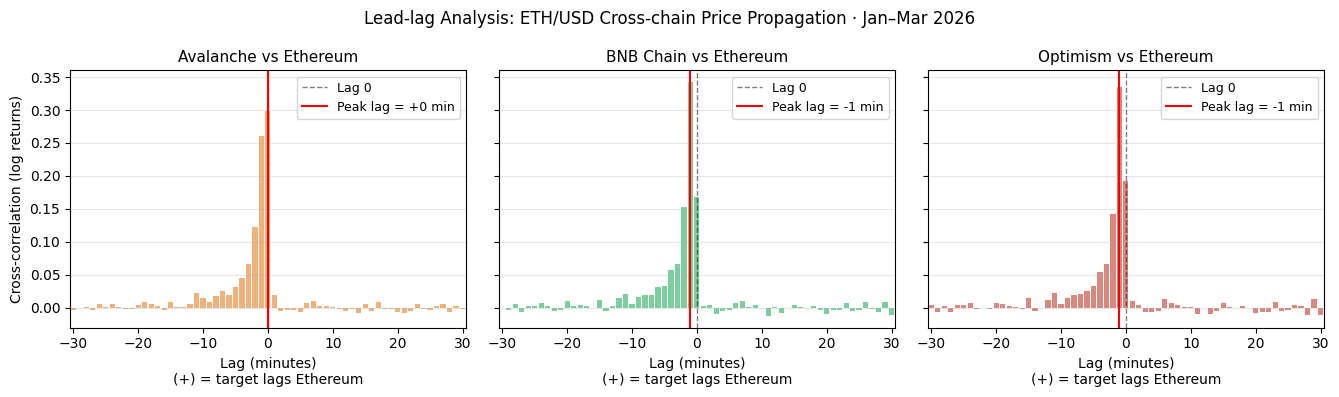

In [2]:
"""Step 2/6: Lead-lag propagation and oracle staleness."""

print("── Step 2: Lead-lag propagation and staleness ─────────────────────")

# Log returns for lead-lag analysis
returns = pd.DataFrame({c: np.log(df[c]).diff() for c in CHAINS}).dropna()
MAX_LAG = 30
REFERENCE = "ethereum"
TARGETS = [c for c in CHAINS if c != REFERENCE]
lags = list(range(-MAX_LAG, MAX_LAG + 1))

leadlag_results = {}
for target in TARGETS:
    ref = returns[REFERENCE].values
    tgt = returns[target].values
    corrs = []
    for lag in lags:
        if lag < 0:
            r = np.corrcoef(ref[-lag:], tgt[:lag])[0, 1]
        elif lag > 0:
            r = np.corrcoef(ref[:-lag], tgt[lag:])[0, 1]
        else:
            r = np.corrcoef(ref, tgt)[0, 1]
        corrs.append(r)
    corrs = np.array(corrs)
    best_idx = int(np.argmax(corrs))
    best_lag = lags[best_idx]
    max_corr = corrs[best_idx]
    zero_corr = corrs[lags.index(0)]
    leadlag_results[target] = {
        "best_lag_min": best_lag,
        "max_correlation": round(max_corr, 4),
        "zero_lag_corr": round(zero_corr, 4),
        "corr_gain": round(max_corr - zero_corr, 4),
        "all_corrs": corrs,
    }

print("Lead-lag summary relative to Ethereum:")
print(f"{'Chain':<14} {'Best Lag':>10} {'Max Corr':>10} {'Zero Corr':>11} {'Gain':>8}")
print("-" * 57)
for t, v in leadlag_results.items():
    print(f"{CHAIN_LABELS[t]:<14} {v['best_lag_min']:>+10} {v['max_correlation']:>10.4f} {v['zero_lag_corr']:>11.4f} {v['corr_gain']:>8.4f}")

# Figure: cross-correlation bar charts (color scheme preserved from original Step 2)
fig, axes = plt.subplots(1, len(TARGETS), figsize=(4.5 * len(TARGETS), 4), sharey=True)
if len(TARGETS) == 1:
    axes = [axes]
colors = ["#e67e22", "#27ae60", "#c0392b"]
for ax, target, color in zip(axes, TARGETS, colors):
    v = leadlag_results[target]
    ax.bar(lags, v["all_corrs"], color=color, alpha=0.6, width=0.8)
    ax.axvline(0, color="black", lw=1.0, linestyle="--", alpha=0.5, label="Lag 0")
    ax.axvline(v["best_lag_min"], color="red", lw=1.5, label=f"Peak lag = {v['best_lag_min']:+d} min")
    ax.set_xlabel("Lag (minutes)\n(+) = target lags Ethereum", fontsize=10)
    ax.set_title(f"{CHAIN_LABELS[target]} vs Ethereum", fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis="y")
    ax.set_xlim(-MAX_LAG - 0.5, MAX_LAG + 0.5)
axes[0].set_ylabel("Cross-correlation (log returns)", fontsize=10)
fig.suptitle(f"Lead-lag Analysis: {ASSET_LABEL} Cross-chain Price Propagation · {PERIOD_LABEL}", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step2_leadlag.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step2_leadlag.png", bbox_inches="tight", dpi=150)
print("Saved: step2_leadlag.pdf / .png")

# Staleness / update frequency
stale_stats = {}
for c in CHAINS:
    price_changed = df[c].diff().abs() > 0
    stale_runs = []
    current_run = 0
    for changed in price_changed:
        if not changed:
            current_run += 1
        else:
            if current_run > 0:
                stale_runs.append(current_run)
            current_run = 0
    if current_run > 0:
        stale_runs.append(current_run)
    stale_runs = np.array(stale_runs)
    update_count = int(price_changed.sum())
    stale_pct = (1 - update_count / len(df)) * 100
    stale_stats[c] = {
        "updates": update_count,
        "stale_pct": round(stale_pct, 2),
        "avg_stale_mins": round(stale_runs.mean(), 2) if len(stale_runs) else 0,
        "max_stale_mins": int(stale_runs.max()) if len(stale_runs) else 0,
        "p95_stale_mins": round(np.percentile(stale_runs, 95), 1) if len(stale_runs) else 0,
    }

stale_df = pd.DataFrame.from_dict(stale_stats, orient="index")
stale_df.index = [CHAIN_LABELS[c] for c in stale_stats.keys()]
stale_df.to_csv(OUTPUT_DIR / "step2_staleness.csv")
print("\nOracle staleness summary:")
print(stale_df.to_string())
print("Saved: step2_staleness.csv")

print("\nLaTeX table: staleness")
lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{Oracle update frequency and stale windows for {ASSET_LABEL} feeds.}}",
    r"\label{tab:staleness}",
    r"\small",
    r"\begin{tabular}{@{}lrrrr@{}}",
    r"\toprule",
    r"\textbf{Chain} & \textbf{Updates} & \textbf{Stale} & \textbf{Avg.} & \textbf{Max} \\",
    r" & & \textbf{time} & \textbf{stale} & \textbf{stale} \\",
    r"\midrule",
]
for c, v in stale_stats.items():
    lines.append(f"{CHAIN_LABELS[c]} & {v['updates']:,} & {v['stale_pct']:.2f}\\% & {v['avg_stale_mins']:.2f}m & {v['max_stale_mins']}m \\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print_latex(lines)

RESULTS["step2"] = {"leadlag": leadlag_results, "stale_stats": stale_stats}
print("Step 2 complete.")

# ── Median-reference sensitivity to each chain ───────────────────────────────
# Quantifies how much the cross-chain oracle-TWAP median changes when each chain
# is excluded. This directly measures whether a stale chain materially shifts the
# median reference.

print("\nMedian-reference leave-one-out sensitivity:")

median_sensitivity_rows = []

# Base median with all chains
median_all = df[CHAINS].median(axis=1)

for dropped in CHAINS:
    subset = [c for c in CHAINS if c != dropped]
    median_loo = df[subset].median(axis=1)

    shift_pct = ((median_all - median_loo).abs() / median_loo) * 100.0

    median_sensitivity_rows.append({
        "dropped_chain": dropped,
        "p50_shift_pct": float(shift_pct.quantile(0.50)),
        "p95_shift_pct": float(shift_pct.quantile(0.95)),
        "p99_shift_pct": float(shift_pct.quantile(0.99)),
        "max_shift_pct": float(shift_pct.max()),
    })

median_sensitivity_df = pd.DataFrame(median_sensitivity_rows)
median_sensitivity_df.to_csv(
    OUTPUT_DIR / "median_reference_loo_sensitivity.csv",
    index=False
)

print(
    median_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)
print("Saved: median_reference_loo_sensitivity.csv")


# ── Ethereum stale-window split ──────────────────────────────────────────────
# Specifically quantifies whether Ethereum's stale windows shift the median more
# than Ethereum's fresh-update minutes.

eth_chain = "ethereum"
median_no_eth = df[[c for c in CHAINS if c != eth_chain]].median(axis=1)
eth_median_shift_pct = ((median_all - median_no_eth).abs() / median_no_eth) * 100.0

# Recompute Ethereum stale run if not already available
eth_changed = df[eth_chain].diff().abs().fillna(np.inf) > 0
eth_stale_run = np.zeros(len(df), dtype=int)
run = 0
for i, is_changed in enumerate(eth_changed):
    run = 0 if is_changed else run + 1
    eth_stale_run[i] = run

eth_stale_mask = pd.Series(eth_stale_run > 0, index=df.index)
eth_fresh_mask = ~eth_stale_mask

eth_stale_rows = []
for label, mask in [
    ("Ethereum fresh-update minutes", eth_fresh_mask),
    ("Ethereum stale minutes", eth_stale_mask),
    ("All minutes", pd.Series(True, index=df.index)),
]:
    s = eth_median_shift_pct[mask]
    eth_stale_rows.append({
        "condition": label,
        "minutes": int(mask.sum()),
        "share_pct": float(mask.mean() * 100.0),
        "p50_shift_pct": float(s.quantile(0.50)),
        "p95_shift_pct": float(s.quantile(0.95)),
        "p99_shift_pct": float(s.quantile(0.99)),
        "max_shift_pct": float(s.max()),
    })

eth_stale_sensitivity_df = pd.DataFrame(eth_stale_rows)
eth_stale_sensitivity_df.to_csv(
    OUTPUT_DIR / "ethereum_stale_median_sensitivity.csv",
    index=False
)

print("\nEthereum stale-window median sensitivity:")
print(
    eth_stale_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)
print("Saved: ethereum_stale_median_sensitivity.csv")

── Step 3: Feasibility Bound Analysis ─────────────────────────────
Base fixed-cost profitability violations over parameter sweep:
exposure         10000    100000   500000   1000000
epsilon C_total                                    
1.10    10        0.0000   0.0000   0.0000   0.0000
        50        0.0000   0.0000   0.0000   0.0000
        100       0.0000   0.0000   0.0000   0.0000
        500       0.0000   0.0000   0.0000   0.0000
1.25    10        0.0000   0.0000   0.0000   0.0000
        50        0.0000   0.0000   0.0000   0.0000
        100       0.0000   0.0000   0.0000   0.0000
        500       0.0000   0.0000   0.0000   0.0000
1.50    10        0.0000   0.0000   0.0000   0.0000
        50        0.0000   0.0000   0.0000   0.0000
        100       0.0000   0.0000   0.0000   0.0000
        500       0.0000   0.0000   0.0000   0.0000
Saved: step3_feasibility_sweep.csv

Theta_obs by Ethereum stale-window bin:
           Mean_Theta  Median_Theta  P95_Theta
stale_bin         

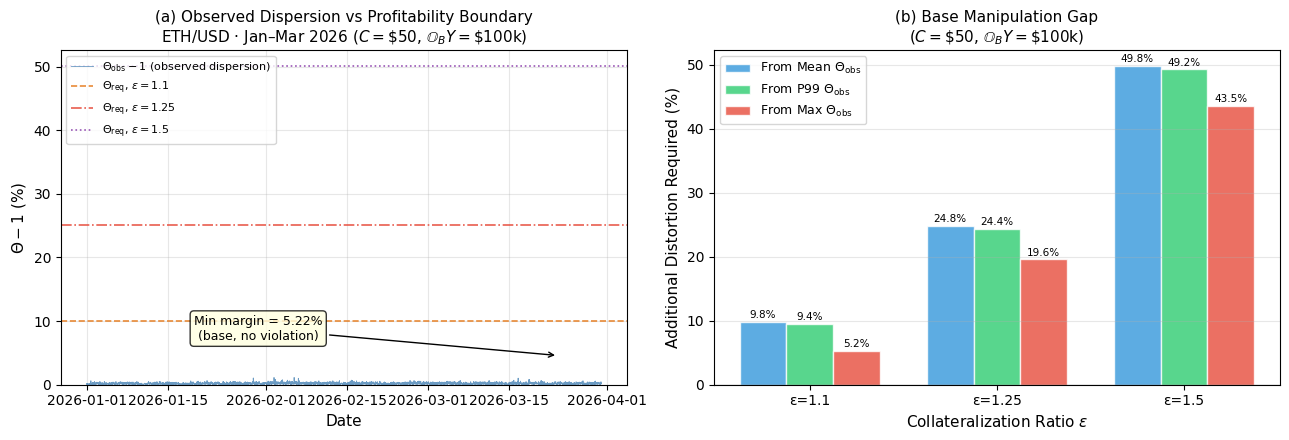

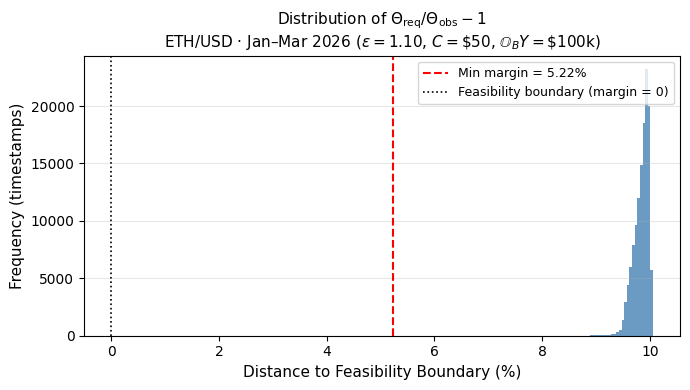

In [3]:
"""
Step 3/6: Feasibility bound and manipulation gap.

Option B version:
  - REP_EXPOSURE and Y_VALUES are treated as notional exposure values OBY directly.
  - Base fixed-cost threshold is:
        Theta_min = epsilon * (1 + C_total / exposure)
    where exposure = OBY.
  - This matches the paper text/table caption:
        C_total=$50, OBY=$100k  ->  Theta_min = 1.10055 for epsilon=1.10.
  - Profitability boundaries are constant horizontal lines in the figure.
  - Step 4 can continue using RESULTS["step3"]["min_profit_injection_pct_base"].
"""

print("── Step 3: Feasibility Bound Analysis ─────────────────────────────")

# ---------------------------------------------------------------------
# Safety/defaults
# ---------------------------------------------------------------------
try:
    RESULTS
except NameError:
    RESULTS = {}

try:
    print_latex
except NameError:
    def print_latex(lines):
        print("\n".join(lines))

try:
    PHI_VALUES
except NameError:
    PHI_VALUES = [0.0, 0.001, 0.003, 0.005, 0.01]  # 0, 10, 30, 50, 100 bps

try:
    SLIP_BPS_VALUES
except NameError:
    SLIP_BPS_VALUES = [0, 5, 10, 30, 50]

try:
    LIQUIDITY_CAP_VALUES
except NameError:
    LIQUIDITY_CAP_VALUES = [None, 100_000, 500_000, 1_000_000]

try:
    REP_PHI
except NameError:
    REP_PHI = 0.005  # 50 bps

try:
    REP_SLIP_BPS
except NameError:
    REP_SLIP_BPS = 10  # 10 bps

try:
    REP_LIQUIDITY_CAP
except NameError:
    REP_LIQUIDITY_CAP = None

# ---------------------------------------------------------------------
# Observed distortion
# ---------------------------------------------------------------------
df["Theta_obs"] = row_max / row_min

# ---------------------------------------------------------------------
# Cost-model helpers
# ---------------------------------------------------------------------
# Option B: exposure is already the notional exposure OBY.
# Do NOT multiply by row_med here.
def exposure_notional(exposure):
    """Return notional exposure OBY."""
    return exposure


def theta_required_fixed(epsilon, c_total, exposure, price_ref=None):
    """
    Base fixed-cost threshold:
        Theta_min = epsilon * (1 + C_total / OBY)

    price_ref is accepted only for backward compatibility with older calls.
    It is intentionally ignored under Option B.
    """
    x_nom = exposure_notional(exposure)
    return epsilon * (1 + c_total / x_nom)


def c_slip(exposure_value, slip_bps):
    """Linear size-dependent slippage/unwind cost in notional units."""
    return (slip_bps / 10_000) * exposure_value


def effective_notional(exposure_value, liquidity_cap=None):
    """Effective extractable notional after destination-chain liquidity limits."""
    if liquidity_cap is None:
        return exposure_value
    return np.minimum(exposure_value, liquidity_cap)


def theta_required_extended(
    epsilon,
    c_fix,
    exposure,
    price_ref=None,
    phi=0.0,
    slip_bps=0.0,
    liquidity_cap=None,
):
    """
    Extended threshold with proportional costs, slippage, and liquidity cap.

    Option B: exposure is already OBY. price_ref is ignored.
    """
    if phi < 0 or phi >= 1:
        raise ValueError("phi must satisfy 0 <= phi < 1")

    x_nom = exposure_notional(exposure)
    x_eff = effective_notional(x_nom, liquidity_cap)
    slip = c_slip(x_nom, slip_bps)

    return (epsilon / (1 - phi)) * (1 + (c_fix + slip) / x_eff)


# Backward-compatible alias used by older code.
def theta_required(epsilon, c_total, exposure, price_ref=None):
    return theta_required_fixed(epsilon, c_total, exposure, price_ref)


# ---------------------------------------------------------------------
# Part 1: Base fixed-cost profitability sweep
# ---------------------------------------------------------------------
feas_rows = []

for epsilon in EPSILON_VALUES:
    for c_total in C_TOTAL_VALUES:
        for exposure in Y_VALUES:
            threshold = theta_required_fixed(epsilon, c_total, exposure)
            violations = df["Theta_obs"] > threshold

            feas_rows.append({
                "epsilon": epsilon,
                "C_total": c_total,
                "exposure": exposure,
                "Theta_min": threshold,
                "pct_profitable": violations.mean() * 100,
                "count": int(violations.sum()),
            })

feas_df = pd.DataFrame(feas_rows)
feas_df.to_csv(OUTPUT_DIR / "step3_feasibility_sweep.csv", index=False)

print("Base fixed-cost profitability violations over parameter sweep:")
print(
    feas_df.pivot_table(
        index=["epsilon", "C_total"],
        columns="exposure",
        values="pct_profitable",
    ).to_string(float_format=lambda x: f"{x:.4f}")
)
print("Saved: step3_feasibility_sweep.csv")


# ---------------------------------------------------------------------
# Part 2: Stale-window conditioning using Ethereum stale run length
# ---------------------------------------------------------------------
run = 0
stale_duration = np.zeros(len(df), dtype=int)
eth_changed = df["ethereum"].diff().abs() > 0

for i, changed in enumerate(eth_changed):
    run = 0 if changed else run + 1
    stale_duration[i] = run

df["eth_stale_mins"] = stale_duration

bins = [0, 5, 15, 30, 60, 999]
labels = ["0-5", "6-15", "16-30", "31-60", ">60"]
df["stale_bin"] = pd.cut(df["eth_stale_mins"], bins=bins, labels=labels)

stale_theta = df.groupby("stale_bin", observed=True)["Theta_obs"].agg(
    Mean_Theta="mean",
    Median_Theta="median",
    P95_Theta=lambda x: np.percentile(x, 95),
).round(6)

stale_theta.to_csv(OUTPUT_DIR / "step3_stale_theta.csv")

print("\nTheta_obs by Ethereum stale-window bin:")
print(stale_theta.to_string())
print("Saved: step3_stale_theta.csv")


# ---------------------------------------------------------------------
# Part 3: Base multiplicative manipulation gap
# ---------------------------------------------------------------------
theta_obs_mean = float(df["Theta_obs"].mean())
theta_obs_p99 = float(df["Theta_obs"].quantile(0.99))
theta_obs_max = float(df["Theta_obs"].max())

gap_rows = []

for eps in EPSILON_VALUES:
    theta_req = theta_required_fixed(eps, REP_C_TOTAL, REP_EXPOSURE)

    gap_rows.append({
        "epsilon": eps,
        "Theta_min": theta_req,
        "Gap_mean_pct": (theta_req / theta_obs_mean - 1) * 100,
        "Gap_P99_pct": (theta_req / theta_obs_p99 - 1) * 100,
        "Gap_max_pct": (theta_req / theta_obs_max - 1) * 100,
    })

gap_df = pd.DataFrame(gap_rows)
gap_df.to_csv(OUTPUT_DIR / "step3_gap.csv", index=False)

most_lenient_eps = min(EPSILON_VALUES)

theta_req_base = theta_required_fixed(
    most_lenient_eps,
    REP_C_TOTAL,
    REP_EXPOSURE,
)

margin_pct_base = (theta_req_base / df["Theta_obs"] - 1) * 100

MIN_PROFIT_INJECTION_PCT_BASE = float(margin_pct_base.min())
MEAN_PROFIT_INJECTION_PCT_BASE = float(margin_pct_base.mean())

print("\nObserved distortion factor:")
print(f"  Theta_obs mean : {theta_obs_mean:.6f} ({(theta_obs_mean - 1) * 100:.4f}%)")
print(f"  Theta_obs P99  : {theta_obs_p99:.6f} ({(theta_obs_p99 - 1) * 100:.4f}%)")
print(f"  Theta_obs max  : {theta_obs_max:.6f} ({(theta_obs_max - 1) * 100:.4f}%)")

print("\nBase-case multiplicative additional distortion required:")
print(gap_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nBase minimum margin to most lenient boundary: {MIN_PROFIT_INJECTION_PCT_BASE:.4f}%")
print("Saved: step3_gap.csv")


# ---------------------------------------------------------------------
# Part 4: Extended proportional/slippage sensitivity
# ---------------------------------------------------------------------
ext_rows = []

for phi in PHI_VALUES:
    for slip_bps in SLIP_BPS_VALUES:
        theta_req_ext = theta_required_extended(
            most_lenient_eps,
            REP_C_TOTAL,
            REP_EXPOSURE,
            phi=phi,
            slip_bps=slip_bps,
            liquidity_cap=None,
        )

        margin_ext = (theta_req_ext / df["Theta_obs"] - 1) * 100

        ext_rows.append({
            "epsilon": most_lenient_eps,
            "phi": phi,
            "phi_bps": phi * 10_000,
            "slip_bps": slip_bps,
            "liquidity_cap": "None",
            "Theta_min_ext": float(theta_req_ext),
            "Gap_max_pct_ext": float((theta_req_ext / theta_obs_max - 1) * 100),
            "Min_margin_pct_ext": float(margin_ext.min()),
            "Mean_margin_pct_ext": float(margin_ext.mean()),
        })

ext_df = pd.DataFrame(ext_rows)
ext_df.to_csv(OUTPUT_DIR / "step3_extended_cost_sensitivity.csv", index=False)

print("\nExtended proportional/slippage sensitivity: min margin by phi/slippage")
print(
    ext_df.pivot_table(
        index="slip_bps",
        columns="phi_bps",
        values="Min_margin_pct_ext",
    ).to_string(float_format=lambda x: f"{x:.2f}")
)
print("Saved: step3_extended_cost_sensitivity.csv")


# ---------------------------------------------------------------------
# Part 4b: Compact cost-sensitivity table for paper
# ---------------------------------------------------------------------
COST_SENSITIVITY_SETTINGS = [
    {
        "setting": "Base case",
        "phi": 0.0,
        "slip_bps": 0,
        "liquidity_cap": None,
    },
    {
        "setting": "Low friction",
        "phi": 0.001,   # 10 bps
        "slip_bps": 5,
        "liquidity_cap": None,
    },
    {
        "setting": "Moderate friction",
        "phi": 0.003,   # 30 bps
        "slip_bps": 10,
        "liquidity_cap": None,
    },
    {
        "setting": "High friction",
        "phi": 0.010,   # 100 bps
        "slip_bps": 50,
        "liquidity_cap": None,
    },
]

cost_sensitivity_rows = []

for setting in COST_SENSITIVITY_SETTINGS:
    theta_req = theta_required_extended(
        most_lenient_eps,
        REP_C_TOTAL,
        REP_EXPOSURE,
        phi=setting["phi"],
        slip_bps=setting["slip_bps"],
        liquidity_cap=setting["liquidity_cap"],
    )

    margin_pct = (theta_req / df["Theta_obs"] - 1) * 100

    cost_sensitivity_rows.append({
        "Cost setting": setting["setting"],
        "phi": setting["phi"],
        "phi_bps": setting["phi"] * 10_000,
        "slip_bps": setting["slip_bps"],
        "liquidity_cap": "None" if setting["liquidity_cap"] is None else setting["liquidity_cap"],
        "Theta_min": float(theta_req),
        "Min_margin_pct": float(margin_pct.min()),
        "Mean_margin_pct": float(margin_pct.mean()),
    })

cost_sensitivity_df = pd.DataFrame(cost_sensitivity_rows)
cost_sensitivity_df.to_csv(OUTPUT_DIR / "step3_cost_sensitivity.csv", index=False)

print("\nCompact cost-sensitivity table:")
print(cost_sensitivity_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("Saved: step3_cost_sensitivity.csv")


# ---------------------------------------------------------------------
# Part 4c: Liquidity-cap sensitivity for representative extended setting
# ---------------------------------------------------------------------
liq_rows = []

for cap in LIQUIDITY_CAP_VALUES:
    theta_req_liq = theta_required_extended(
        most_lenient_eps,
        REP_C_TOTAL,
        REP_EXPOSURE,
        phi=REP_PHI,
        slip_bps=REP_SLIP_BPS,
        liquidity_cap=cap,
    )

    margin_liq = (theta_req_liq / df["Theta_obs"] - 1) * 100

    liq_rows.append({
        "epsilon": most_lenient_eps,
        "phi": REP_PHI,
        "phi_bps": REP_PHI * 10_000,
        "slip_bps": REP_SLIP_BPS,
        "liquidity_cap": "None" if cap is None else cap,
        "Theta_min_ext": float(theta_req_liq),
        "Min_margin_pct_ext": float(margin_liq.min()),
        "Mean_margin_pct_ext": float(margin_liq.mean()),
    })

liq_df = pd.DataFrame(liq_rows)
liq_df.to_csv(OUTPUT_DIR / "step3_liquidity_sensitivity.csv", index=False)

print("\nLiquidity-cap sensitivity for representative extended setting:")
print(liq_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("Saved: step3_liquidity_sensitivity.csv")


# Representative extended value exported for optional sensitivity text.
theta_req_ext_rep = theta_required_extended(
    most_lenient_eps,
    REP_C_TOTAL,
    REP_EXPOSURE,
    phi=REP_PHI,
    slip_bps=REP_SLIP_BPS,
    liquidity_cap=REP_LIQUIDITY_CAP,
)

margin_pct_ext = (theta_req_ext_rep / df["Theta_obs"] - 1) * 100

MIN_PROFIT_INJECTION_PCT_EXTENDED = float(margin_pct_ext.min())
MEAN_PROFIT_INJECTION_PCT_EXTENDED = float(margin_pct_ext.mean())

print(
    f"\nRepresentative extended minimum margin "
    f"(phi={REP_PHI * 10_000:.0f} bps, slip={REP_SLIP_BPS} bps, "
    f"cap={'None' if REP_LIQUIDITY_CAP is None else REP_LIQUIDITY_CAP}): "
    f"{MIN_PROFIT_INJECTION_PCT_EXTENDED:.4f}%"
)


# ---------------------------------------------------------------------
# Part 5: Base feasibility-bound figure
# Color scheme preserved.
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
plot_step = 30
plot_obs = df["Theta_obs"].iloc[::plot_step]
plot_idx = df.index[::plot_step]

ax.plot(
    plot_idx,
    (plot_obs - 1) * 100,
    color="steelblue",
    lw=0.6,
    alpha=0.8,
    label=r"$\Theta_{\rm obs}-1$ (observed dispersion)",
)

colors_req = ["#e67e22", "#e74c3c", "#8e44ad"]
linestyles = ["--", "-.", ":"]

for eps, col, ls in zip(EPSILON_VALUES, colors_req, linestyles):
    theta_req = theta_required_fixed(eps, REP_C_TOTAL, REP_EXPOSURE)
    boundary_pct = (theta_req - 1) * 100

    ax.axhline(
        boundary_pct,
        color=col,
        lw=1.2,
        linestyle=ls,
        alpha=0.9,
        label=fr"$\Theta_{{\rm req}}$, $\epsilon={eps}$",
    )

    violation = plot_obs.values >= theta_req
    if violation.any():
        boundary_arr = np.full(len(plot_obs), boundary_pct, dtype=float)
        ax.fill_between(
            plot_idx,
            (plot_obs - 1) * 100,
            boundary_arr,
            where=violation,
            color="red",
            alpha=0.5,
            label="Violation (attack profitable)",
        )

obs_max_pct = float((df["Theta_obs"] - 1).max() * 100)
peak_idx = int(df["Theta_obs"].values.argmax())

ax.annotate(
    f"Min margin = {MIN_PROFIT_INJECTION_PCT_BASE:.2f}%\n(base, no violation)",
    xy=(df.index[peak_idx], obs_max_pct),
    xytext=(df.index[len(df) // 3], obs_max_pct + 2.5),
    arrowprops=dict(arrowstyle="->", color="black", lw=1),
    fontsize=9,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", alpha=0.8),
)

ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel(r"$\Theta - 1$ (%)", fontsize=11)
ax.set_title(
    f"(a) Observed Dispersion vs Profitability Boundary\n"
    f"{ASSET_LABEL} · {PERIOD_LABEL} "
    f"($C=\\${REP_C_TOTAL}$, $\\mathbb{{O}}_B Y=\\${REP_EXPOSURE/1000:.0f}$k)",
    fontsize=11,
)
ax.legend(fontsize=8, loc="upper left")
ax.grid(True, alpha=0.3)
ax.set_ylim(0)

ax2 = axes[1]

obs_scn = {
    "Mean": (theta_obs_mean - 1) * 100,
    "P99": (theta_obs_p99 - 1) * 100,
    "Max": (theta_obs_max - 1) * 100,
}

x = np.arange(len(EPSILON_VALUES))
width = 0.25
offset = [-width, 0, width]
colors_bar = ["#3498db", "#2ecc71", "#e74c3c"]

for idx, (label, obs_pct) in enumerate(obs_scn.items()):
    theta_obs_val = 1 + obs_pct / 100
    gaps = []

    for eps in EPSILON_VALUES:
        theta_r = theta_required_fixed(eps, REP_C_TOTAL, REP_EXPOSURE)
        gaps.append(max((theta_r / theta_obs_val - 1) * 100, 0))

    bars = ax2.bar(
        x + offset[idx],
        gaps,
        width,
        label=f"From {label} $\\Theta_{{\\rm obs}}$",
        color=colors_bar[idx],
        alpha=0.8,
        edgecolor="white",
    )

    for bar, gap in zip(bars, gaps):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{gap:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.5,
        )

ax2.set_xlabel(r"Collateralization Ratio $\epsilon$", fontsize=11)
ax2.set_ylabel("Additional Distortion Required (%)", fontsize=11)
ax2.set_title(
    f"(b) Base Manipulation Gap\n"
    f"($C=\\${REP_C_TOTAL}$, $\\mathbb{{O}}_B Y=\\${REP_EXPOSURE/1000:.0f}$k)",
    fontsize=11,
)
ax2.set_xticks(x)
ax2.set_xticklabels([f"ε={e}" for e in EPSILON_VALUES], fontsize=10)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis="y")
ax2.axhline(0, color="black", lw=0.8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_feasibility_boundary.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step3_feasibility_boundary.png", bbox_inches="tight", dpi=150)
print("Saved: step3_feasibility_boundary.pdf / .png")


# ---------------------------------------------------------------------
# Part 6: Base distance-to-bound histogram
# Color scheme preserved.
# ---------------------------------------------------------------------
fig2, ax3 = plt.subplots(figsize=(7, 4))

ax3.hist(
    margin_pct_base,
    bins=100,
    color="steelblue",
    edgecolor="none",
    alpha=0.8,
)

ax3.axvline(
    MIN_PROFIT_INJECTION_PCT_BASE,
    color="red",
    lw=1.5,
    linestyle="--",
    label=f"Min margin = {MIN_PROFIT_INJECTION_PCT_BASE:.2f}%",
)

ax3.axvline(
    0,
    color="black",
    lw=1.2,
    linestyle=":",
    label="Feasibility boundary (margin = 0)",
)

ax3.set_xlabel("Distance to Feasibility Boundary (%)", fontsize=11)
ax3.set_ylabel("Frequency (timestamps)", fontsize=11)
ax3.set_title(
    r"Distribution of $\Theta_{\rm req}/\Theta_{\rm obs} - 1$"
    + "\n"
    + f"{ASSET_LABEL} · {PERIOD_LABEL} "
      f"($\\epsilon={most_lenient_eps:.2f}$, "
      f"$C=\\${REP_C_TOTAL}$, "
      f"$\\mathbb{{O}}_B Y=\\${REP_EXPOSURE/1000:.0f}$k)",
    fontsize=11,
)

ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step3_margin_distribution.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step3_margin_distribution.png", bbox_inches="tight", dpi=150)
print("Saved: step3_margin_distribution.pdf / .png")


# ---------------------------------------------------------------------
# LaTeX table: base manipulation gap
# ---------------------------------------------------------------------
print("\nLaTeX table: base manipulation gap")

lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{Multiplicative additional distortion required above observed "
    rf"{ASSET_LABEL} cross-chain distortion to reach the attacker-favorable "
    rf"base-case boundary ($\Ctotal=\${REP_C_TOTAL}$, "
    rf"$\OB Y=\${REP_EXPOSURE/1000:.0f}\mathrm{{k}}$).}}",
    r"\label{tab:gap}",
    r"\small",
    r"\begin{tabular}{@{}lrrrr@{}}",
    r"\toprule",
    r"\textbf{$\epsilon$} & \textbf{$\Theta_{\min}$} & "
    r"\textbf{Gap/mean} & \textbf{Gap/P99} & \textbf{Gap/max} \\",
    r"\midrule",
]

for _, row in gap_df.iterrows():
    lines.append(
        f"{row['epsilon']:.2f} & "
        f"{row['Theta_min']:.4f} & "
        f"{row['Gap_mean_pct']:.2f}\\% & "
        f"{row['Gap_P99_pct']:.2f}\\% & "
        f"{row['Gap_max_pct']:.2f}\\% \\\\"
    )

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

print_latex(lines)


# ---------------------------------------------------------------------
# LaTeX table: compact cost sensitivity
# ---------------------------------------------------------------------
print("\nLaTeX table: compact cost sensitivity")

lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{Profitability-boundary sensitivity to proportional costs and slippage "
    rf"($\epsilon={most_lenient_eps:.2f}$, "
    rf"$C_{{\mathrm{{fix}}}}=\${REP_C_TOTAL}$, "
    rf"$\OB Y=\${REP_EXPOSURE/1000:.0f}\mathrm{{k}}$, no liquidity cap).}}",
    r"\label{tab:cost_sensitivity}",
    r"\small",
    r"\begin{tabular}{@{}lccc@{}}",
    r"\toprule",
    r"\textbf{Cost setting} & $\boldsymbol{\phi}$ & \textbf{Slip.} & "
    r"\makecell{\textbf{Add. injection}\\\textbf{above max obs.}} \\",
    r"\midrule",
]

for _, row in cost_sensitivity_df.iterrows():
    lines.append(
        f"{row['Cost setting']} & "
        f"{row['phi_bps']:.0f} bps & "
        f"{row['slip_bps']:.0f} bps & "
        f"{row['Min_margin_pct']:.2f}\\% \\\\"
    )

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

print_latex(lines)


# ---------------------------------------------------------------------
# Store outputs
# ---------------------------------------------------------------------
RESULTS["step3"] = {
    "feasibility": feas_df,
    "gap": gap_df,
    "extended_cost_sensitivity": ext_df,
    "cost_sensitivity": cost_sensitivity_df,
    "liquidity_sensitivity": liq_df,
    "theta_obs_mean": theta_obs_mean,
    "theta_obs_p99": theta_obs_p99,
    "theta_obs_max": theta_obs_max,
    "theta_min_base_rep": theta_req_base,
    "min_profit_injection_pct": MIN_PROFIT_INJECTION_PCT_BASE,  # backward compatibility
    "min_profit_injection_pct_base": MIN_PROFIT_INJECTION_PCT_BASE,
    "mean_profit_injection_pct_base": MEAN_PROFIT_INJECTION_PCT_BASE,
    "min_profit_injection_pct_extended": MIN_PROFIT_INJECTION_PCT_EXTENDED,
    "mean_profit_injection_pct_extended": MEAN_PROFIT_INJECTION_PCT_EXTENDED,
    "margin_pct": margin_pct_base,  # backward compatibility
    "margin_pct_base": margin_pct_base,
    "margin_pct_extended": margin_pct_ext,
    "rep_phi": REP_PHI,
    "rep_slip_bps": REP_SLIP_BPS,
    "rep_liquidity_cap": REP_LIQUIDITY_CAP,
    "option_b_exposure_is_notional": True,
}

print("Step 3 complete.")

── Step 4: xTCP Sensitivity Boundary ─────────────────────────────
FRR sweep:
   delta |    FRR (%) |    Verdict
------------------------------------
  0.050% |   32.9079% |   UNUSABLE
  0.100% |   15.9264% |   UNUSABLE
  0.200% |    7.0868% |   UNUSABLE
  0.300% |    2.9892% |       HIGH
  0.500% |    0.1709% |   SELECTED
  0.800% |    0.0345% |         OK
  1.000% |    0.0137% |         OK
  2.000% |    0.0014% |         OK
  5.000% |    0.0000% |         OK
Shared attack trials generated: 100 runs × 500 attacks × 1 theta values × 5 ramp steps

Detection boundary curve:
   Theta |  Distortion |  Mean Det. |     95% CI |     Status
--------------------------------------------------------------
   1.010 |       1.00% |      98.7% | ±    0.1% |   DETECTED ← boundary

Cross-step values used by Step 4:
  P99 natural deviation (Step 1): 0.5534%
  Min profit-injection margin (Step 3): 5.2218%
  Detection boundary: 1.00% (Θ=1.010)
  Safety margin: 4.22 percentage points
Saved: step4_boundary

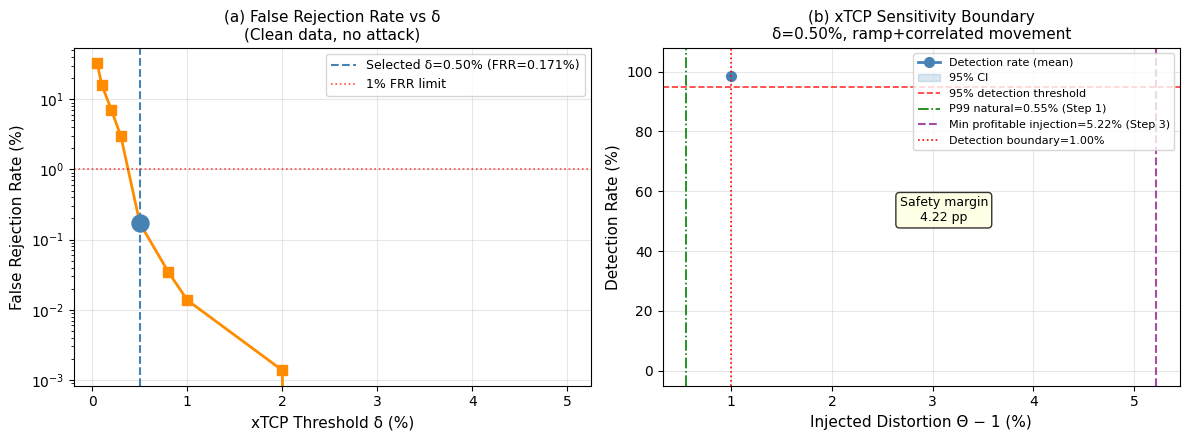

In [4]:
"""Step 4/6: xTCP detection boundary.
Uses Step 1 P99 and Step 3 minimum profit-injection margin automatically.
Creates shared attack trials that Step 6 reuses, so Q3 and Q5 report the same
xTCP detection value at the sensitivity boundary.
"""

print("── Step 4: xTCP Sensitivity Boundary ─────────────────────────────")

P99_NATURAL_PCT = RESULTS["step1"]["p99_natural_pct"]
MIN_PROFIT_INJECTION_PCT = RESULTS["step3"]["min_profit_injection_pct"]

# Clean-data FRR sweep. This is independent of attack-trial generation.
DELTA_SWEEP = [0.0005, 0.001, 0.002, 0.003, 0.005, 0.008, 0.010, 0.020, 0.050]
frr_rng = np.random.default_rng(SEED)
sample_rows = df.copy()

frr_rates = {}
for delta in DELTA_SWEEP:
    rejected = 0
    for _, row in sample_rows.iterrows():
        base = {c: row[c] for c in CHAINS}
        noisy = build_injected_prices(base)
        med = np.median(list(noisy.values()))
        for c in CHAINS:
            if abs(noisy[c] - med) / med > delta:
                rejected += 1
    frr_rates[delta] = rejected / (len(sample_rows) * len(CHAINS)) * 100

print("FRR sweep:")
print(f"{'delta':>8} | {'FRR (%)':>10} | {'Verdict':>10}")
print("-" * 36)
for delta in DELTA_SWEEP:
    rate = frr_rates[delta]
    verdict = "SELECTED" if delta == DELTA else ("OK" if rate < 1.0 else ("HIGH" if rate < 5.0 else "UNUSABLE"))
    print(f"{delta*100:>7.3f}% | {rate:>9.4f}% | {verdict:>10}")

# Boundary detection curve. These theta values are shared with Step 6.
THETA_BOUNDARY = [
    1.010
]

def theta_key(theta):
    return f"{theta:.3f}"


def generate_shared_attack_trials(df, theta_values, rng_seed):
    """Generate all attack randomness once.

    Step 4 and Step 6 both reuse the returned object. Each trial contains:
      - same sampled start timestamp
      - same attacked chain
      - same ramp window
      - same noisy prices at every ramp step

    This prevents Q3 and Q5 from reporting different detection rates simply
    because they sampled different Monte Carlo attacks.
    """
    rng = np.random.default_rng(rng_seed)
    valid_idxs = np.arange(1, len(df) - RAMP_STEPS + 1)  # idx-1 exists and full ramp fits
    shared = []

    for run in range(N_RUNS):
        run_idxs = rng.choice(valid_idxs, size=N_ATTACKS, replace=False)
        run_chains = rng.choice(CHAINS, size=N_ATTACKS, replace=True)
        run_trials = {theta_key(theta): [] for theta in theta_values}

        for theta in theta_values:
            key = theta_key(theta)
            for idx, attacked_chain in zip(run_idxs, run_chains):
                prev_clean_price = float(df.iloc[idx - 1][attacked_chain])
                step_payloads = []

                for step in range(RAMP_STEPS):
                    row_idx = int(idx + step)
                    base_row = df.iloc[row_idx]
                    base_prices = {c: float(base_row[c]) for c in CHAINS}
                    partial_theta = 1.0 + (float(theta) - 1.0) * ((step + 1) / RAMP_STEPS)
                    noisy = build_injected_prices(
                        base_prices,
                        attacked_chain=attacked_chain,
                        partial_theta=partial_theta,
                    )
                    step_payloads.append({
                        "time": df.index[row_idx],
                        "partial_theta": partial_theta,
                        "noisy": noisy,
                    })

                run_trials[key].append({
                    "idx": int(idx),
                    "attacked_chain": attacked_chain,
                    "prev_clean_price": prev_clean_price,
                    "step_payloads": step_payloads,
                })

        shared.append(run_trials)

    return shared


# Use a separate seed for attacks so changing FRR code does not change attack trials.
SHARED_ATTACK_TRIALS = generate_shared_attack_trials(
    df=df,
    theta_values=THETA_BOUNDARY,
    rng_seed=SEED + 404,
)
print(f"Shared attack trials generated: {N_RUNS} runs × {N_ATTACKS} attacks × {len(THETA_BOUNDARY)} theta values × {RAMP_STEPS} ramp steps")


def evaluate_xtcp_trial(trial, delta):
    attacked_chain = trial["attacked_chain"]
    for payload in trial["step_payloads"]:
        noisy = payload["noisy"]
        if xtcp_x1(noisy, attacked_chain, delta):
            return True
    return False


all_runs = np.zeros((N_RUNS, len(THETA_BOUNDARY)))
for run in range(N_RUNS):
    for k, theta in enumerate(THETA_BOUNDARY):
        key = theta_key(theta)
        detected = sum(evaluate_xtcp_trial(trial, DELTA) for trial in SHARED_ATTACK_TRIALS[run][key])
        all_runs[run, k] = detected / N_ATTACKS * 100

det_mean = all_runs.mean(axis=0)
det_ci = 1.96 * all_runs.std(axis=0, ddof=1) / np.sqrt(all_runs.shape[0])

boundary_theta = None
boundary_idx = None
for k, theta in enumerate(THETA_BOUNDARY):
    if det_mean[k] >= 95:
        boundary_theta = theta
        boundary_idx = k
        break
if boundary_theta is None:
    boundary_theta = THETA_BOUNDARY[-1]
    boundary_idx = len(THETA_BOUNDARY) - 1

det_pct = (boundary_theta - 1) * 100
safety_margin_pp = MIN_PROFIT_INJECTION_PCT - det_pct

print("\nDetection boundary curve:")
print(f"{'Theta':>8} | {'Distortion':>11} | {'Mean Det.':>10} | {'95% CI':>10} | {'Status':>10}")
print("-" * 62)
for k, theta in enumerate(THETA_BOUNDARY):
    mean = det_mean[k]
    ci = det_ci[k]
    status = "DETECTED" if mean >= 95 else ("PARTIAL" if mean >= 10 else "MISSED")
    marker = " ← boundary" if theta == boundary_theta else ""
    print(f"{theta:>8.3f} | {(theta - 1) * 100:>10.2f}% | {mean:>9.1f}% | ±{ci:>7.1f}% | {status:>10}{marker}")

print("\nCross-step values used by Step 4:")
print(f"  P99 natural deviation (Step 1): {P99_NATURAL_PCT:.4f}%")
print(f"  Min profit-injection margin (Step 3): {MIN_PROFIT_INJECTION_PCT:.4f}%")
print(f"  Detection boundary: {det_pct:.2f}% (Θ={boundary_theta:.3f})")
print(f"  Safety margin: {safety_margin_pp:.2f} percentage points")

# Figure (color scheme preserved from original Step 4)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (b) Detection curve
ax = axes[1]
theta_pcts = [(t - 1) * 100 for t in THETA_BOUNDARY]
ax.plot(theta_pcts, det_mean, "o-", color="steelblue", lw=2, markersize=7, label="Detection rate (mean)")
ax.fill_between(theta_pcts, np.clip(det_mean - det_ci, 0, 100), np.clip(det_mean + det_ci, 0, 100), alpha=0.2, color="steelblue", label="95% CI")
ax.axhline(95, color="red", lw=1.2, linestyle="--", alpha=0.8, label="95% detection threshold")
ax.axvline(P99_NATURAL_PCT, color="green", lw=1.2, linestyle="-.", label=f"P99 natural={P99_NATURAL_PCT:.2f}% (Step 1)")
ax.axvline(MIN_PROFIT_INJECTION_PCT, color="purple", lw=1.5, linestyle="--", alpha=0.7, label=f"Min profitable injection={MIN_PROFIT_INJECTION_PCT:.2f}% (Step 3)")
ax.axvline(det_pct, color="red", lw=1.2, linestyle=":", label=f"Detection boundary={det_pct:.2f}%")
ax.annotate(
    f"Safety margin\n{safety_margin_pp:.2f} pp",
    xy=((MIN_PROFIT_INJECTION_PCT + det_pct) / 2, 50),
    fontsize=9,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", alpha=0.8),
)
ax.set_xlabel("Injected Distortion Θ − 1 (%)", fontsize=11)
ax.set_ylabel("Detection Rate (%)", fontsize=11)
ax.set_title(f"(b) xTCP Sensitivity Boundary\nδ={DELTA*100:.2f}%, ramp+correlated movement", fontsize=11)
ax.legend(fontsize=8, loc="upper right")
ax.grid(True, alpha=0.3)
ax.set_ylim(-5, 108)

# (a) FRR curve
ax2 = axes[0]
delta_pcts = [d * 100 for d in DELTA_SWEEP]
frr_vals = [frr_rates[d] for d in DELTA_SWEEP]
ax2.plot(delta_pcts, frr_vals, "s-", color="darkorange", lw=2, markersize=7)
ax2.axvline(DELTA * 100, color="steelblue", lw=1.5, linestyle="--", label=f"Selected δ={DELTA*100:.2f}% (FRR={frr_rates[DELTA]:.3f}%)")
ax2.axhline(1.0, color="red", lw=1.2, linestyle=":", alpha=0.7, label="1% FRR limit")
ax2.scatter([DELTA * 100], [frr_rates[DELTA]], s=150, color="steelblue", zorder=5)
ax2.set_xlabel("xTCP Threshold δ (%)", fontsize=11)
ax2.set_ylabel("False Rejection Rate (%)", fontsize=11)
ax2.set_title("(a) False Rejection Rate vs δ\n(Clean data, no attack)", fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_yscale("log")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step4_boundary.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step4_boundary.png", bbox_inches="tight", dpi=150)
print("Saved: step4_boundary.pdf / .png")

print("\nLaTeX table: detection boundary")
lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{xTCP detection in the sensitivity region ($\delta={DELTA*100:.1f}\%$, ramp attack, {N_RUNS} bootstrap runs, $N={N_ATTACKS}$).}}",
    r"\label{tab:boundary}",
    r"\small",
    r"\begin{tabular}{@{}cccc@{}}",
    r"\toprule",
    r"\textbf{$\Theta$} & \textbf{Distortion} & \textbf{Detection (\%)} & \textbf{Status} \\",
    r"\midrule",
]
for k, theta in enumerate(THETA_BOUNDARY):
    mean = det_mean[k]
    ci = det_ci[k]
    status = r"\textbf{Boundary}" if theta == boundary_theta else ("Detected" if mean >= 95 else ("Partial" if mean >= 10 else "Missed"))
    theta_s = rf"\textbf{{{theta:.3f}}}" if theta == boundary_theta else f"{theta:.3f}"
    dist_s = rf"\textbf{{{(theta - 1) * 100:.2f}\%}}" if theta == boundary_theta else f"{(theta - 1) * 100:.2f}\\%"
    det_s = rf"$\mathbf{{{mean:.1f}\pm{ci:.1f}}}$" if theta == boundary_theta else rf"${mean:.1f}\pm{ci:.1f}$"
    lines.append(f"{theta_s} & {dist_s} & {det_s} & {status} " + r"\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print_latex(lines)

RESULTS["step4"] = {
    "frr_rates": frr_rates,
    "theta_boundary": THETA_BOUNDARY,
    "theta_key": theta_key,
    "shared_attack_trials": SHARED_ATTACK_TRIALS,
    "det_mean": det_mean,
    "det_ci": det_ci,
    "boundary_theta": boundary_theta,
    "boundary_idx": boundary_idx,
    "det_pct": det_pct,
    "safety_margin_pp": safety_margin_pp,
}
print("Step 4 complete.")


── Step 5: xOCB Activation and Effective Suspension ───────────────
Global xOCB activation:
   delta |   Activations |   Rate (%) |  Per day
----------------------------------------------------
   0.10% |        73,104 |   57.0412% |  821.39
   0.20% |        35,661 |   27.8254% |  400.69
   0.30% |        15,166 |   11.8336% |  170.40
   0.50% |           850 |    0.6632% |    9.55 ← selected
   0.80% |           172 |    0.1342% |    1.93
   1.00% |            66 |    0.0515% |    0.74
   2.00% |             7 |    0.0055% |    0.08
   5.00% |             0 |    0.0000% |    0.00

Effective suspension by cooldown scenario:

Cooldown = Conservative (5 min)
   delta |    Acts. |    Susp. h |   Uptime
--------------------------------------------
   0.10% |   73,104 |    1628.3h |   23.77%
   0.20% |   35,661 |     976.3h |   54.29%
   0.30% |   15,166 |     540.5h |   74.70%
   0.50% |      850 |      59.5h |   97.21%
   0.80% |      172 |      11.3h |   99.47%
   1.00% |       66 |    

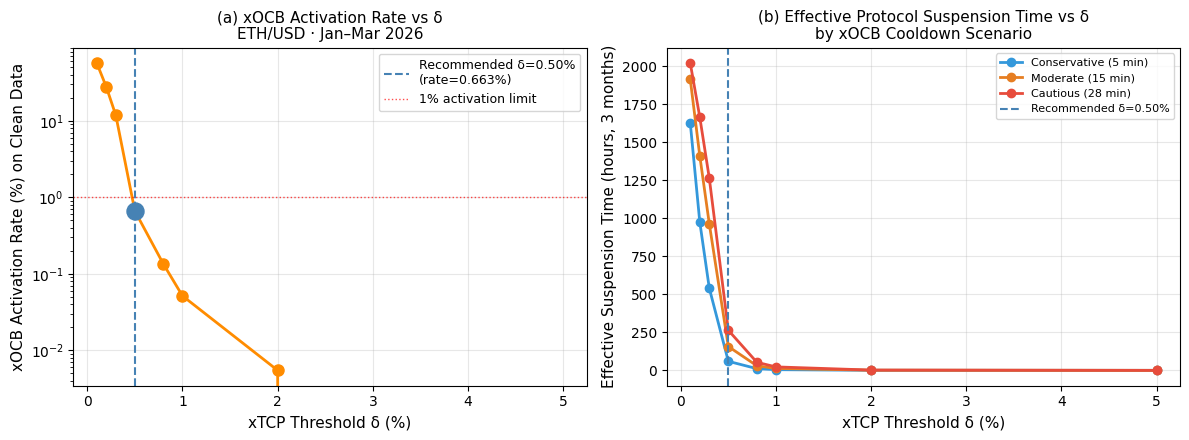

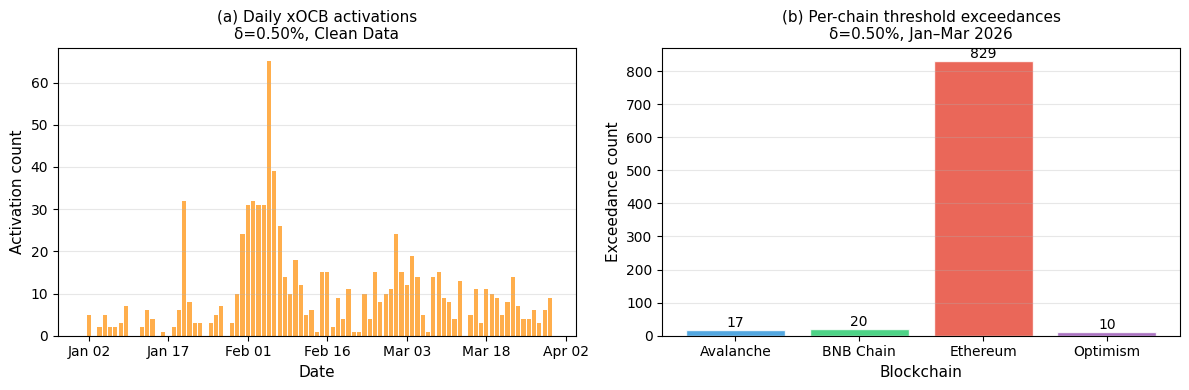

In [5]:
"""Step 5/6: xOCB activation and effective suspension time.
Uses DELTA selected in the shared config and staleness from Step 2 for the cautious scenario.
"""

print("── Step 5: xOCB Activation and Effective Suspension ───────────────")

# Cautious cooldown is derived from Step 2 Ethereum average stale window.
eth_avg_stale = RESULTS["step2"]["stale_stats"]["ethereum"]["avg_stale_mins"]
COOLDOWN_SCENARIOS = {
    "Conservative (5 min)": 5,
    f"Moderate ({COOLDOWN_MINS} min)": COOLDOWN_MINS,
    f"Cautious ({round(eth_avg_stale):.0f} min)": int(round(eth_avg_stale)),
}
DELTA_VALUES = [0.001, 0.002, 0.003, DELTA, 0.008, 0.010, 0.020, 0.050]
DELTA_VALUES = sorted(set(DELTA_VALUES))
RECOMMENDED_DELTA = DELTA

# Per-chain rates
global_rates = {}
global_activations = {}
global_violation_series = {}
per_chain_rates = {}

print("Global xOCB activation:")
print(f"{'delta':>8} | {'Activations':>13} | {'Rate (%)':>10} | {'Per day':>8}")
print("-" * 52)
for delta in DELTA_VALUES:
    any_violation = pd.Series(False, index=df.index)
    for chain in CHAINS:
        deviation = ((df[chain] - row_med) / row_med).abs()
        any_violation = any_violation | (deviation > delta)
    n_activations = int(any_violation.sum())
    rate = any_violation.mean() * 100
    per_day = n_activations / TOTAL_DAYS
    global_rates[delta] = rate
    global_activations[delta] = n_activations
    global_violation_series[delta] = any_violation
    marker = " ← selected" if delta == RECOMMENDED_DELTA else ""
    print(f"{delta*100:>7.2f}% | {n_activations:>13,} | {rate:>9.4f}% | {per_day:>7.2f}{marker}")

for chain in CHAINS:
    deviation = ((df[chain] - row_med) / row_med).abs()
    per_chain_rates[chain] = [(deviation > delta).mean() * 100 for delta in DELTA_VALUES]

# Effective suspension table
suspension_summary = []
print("\nEffective suspension by cooldown scenario:")
for label, cooldown_mins in COOLDOWN_SCENARIOS.items():
    print(f"\nCooldown = {label}")
    print(f"{'delta':>8} | {'Acts.':>8} | {'Susp. h':>10} | {'Uptime':>8}")
    print("-" * 44)
    for delta in DELTA_VALUES:
        susp_mins, merged = effective_suspension_minutes(global_violation_series[delta], cooldown_mins)
        susp_hours = susp_mins / 60
        uptime = max((1 - susp_mins / TOTAL_MINS) * 100, 0)
        suspension_summary.append({
            "cooldown_label": label,
            "cooldown_mins": cooldown_mins,
            "delta": delta,
            "activations": global_activations[delta],
            "rate_pct": global_rates[delta],
            "susp_hours": susp_hours,
            "uptime_pct": uptime,
            "merged_windows": len(merged),
        })
        marker = " ★" if delta == RECOMMENDED_DELTA and cooldown_mins == COOLDOWN_MINS else ""
        print(f"{delta*100:>7.2f}% | {global_activations[delta]:>8,} | {susp_hours:>9.1f}h | {uptime:>7.2f}%{marker}")

suspension_df = pd.DataFrame(suspension_summary)
suspension_df.to_csv(OUTPUT_DIR / "step5_xocb_suspension.csv", index=False)
print("\nSaved: step5_xocb_suspension.csv")

# Recommended delta details
any_violation = global_violation_series[RECOMMENDED_DELTA]
n_act = global_activations[RECOMMENDED_DELTA]
rate = global_rates[RECOMMENDED_DELTA]
per_day = n_act / TOTAL_DAYS
activation_idx = np.where(any_violation.values)[0]
if len(activation_idx) > 0:
    gaps = np.diff(activation_idx)
    cluster_breaks = np.where(gaps > 1)[0]
    n_clusters = len(cluster_breaks) + 1
    avg_burst_duration = len(activation_idx) / n_clusters
else:
    n_clusters = 0
    avg_burst_duration = 0.0

daily_counts = any_violation.resample("D").sum()
zero_days = int((daily_counts == 0).sum())
high_days = int((daily_counts > 10).sum())

susp_mod_mins, merged_mod = effective_suspension_minutes(any_violation, COOLDOWN_MINS)
susp_mod_hours = susp_mod_mins / 60
uptime_mod = max((1 - susp_mod_mins / TOTAL_MINS) * 100, 0)

print("\nSelected δ summary:")
print(f"  Activations: {n_act:,}")
print(f"  Rate: {rate:.4f}%")
print(f"  Activations/day: {per_day:.2f}")
print(f"  Bursts: {n_clusters:,}; avg burst duration: {avg_burst_duration:.1f} min")
print(f"  Zero-activation days: {zero_days}/{len(daily_counts)}; days >10 activations: {high_days}/{len(daily_counts)}")
print(f"  Effective suspension ({COOLDOWN_MINS} min): {susp_mod_hours:.1f}h; uptime: {uptime_mod:.2f}%")

# Figure 1: activation rate + suspension time (color scheme preserved)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
delta_pcts = [d * 100 for d in DELTA_VALUES]
global_rates_list = [global_rates[d] for d in DELTA_VALUES]
ax.plot(delta_pcts, global_rates_list, "o-", color="darkorange", lw=2, markersize=8)
ax.axvline(RECOMMENDED_DELTA * 100, color="steelblue", lw=1.5, linestyle="--",
           label=f"Recommended δ={RECOMMENDED_DELTA*100:.2f}%\n(rate={global_rates[RECOMMENDED_DELTA]:.3f}%)")
ax.axhline(1.0, color="red", lw=1.0, linestyle=":", alpha=0.7, label="1% activation limit")
ax.set_xlabel("xTCP Threshold δ (%)", fontsize=11)
ax.set_ylabel("xOCB Activation Rate (%) on Clean Data", fontsize=11)
ax.set_title(f"(a) xOCB Activation Rate vs δ\n{ASSET_LABEL} · {PERIOD_LABEL}", fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_yscale("log")
ax.scatter([RECOMMENDED_DELTA * 100], [global_rates[RECOMMENDED_DELTA]], s=150, color="steelblue", zorder=5)

ax2 = axes[1]
colors_cd = ["#3498db", "#e67e22", "#e74c3c"]
for (label, cooldown_mins), color in zip(COOLDOWN_SCENARIOS.items(), colors_cd):
    susp_hours = [effective_suspension_minutes(global_violation_series[d], cooldown_mins)[0] / 60 for d in DELTA_VALUES]
    ax2.plot(delta_pcts, susp_hours, "o-", color=color, lw=2, markersize=6, label=label)
ax2.axvline(RECOMMENDED_DELTA * 100, color="steelblue", lw=1.5, linestyle="--", label=f"Recommended δ={RECOMMENDED_DELTA*100:.2f}%")
ax2.set_xlabel("xTCP Threshold δ (%)", fontsize=11)
ax2.set_ylabel("Effective Suspension Time (hours, 3 months)", fontsize=11)
ax2.set_title("(b) Effective Protocol Suspension Time vs δ\nby xOCB Cooldown Scenario", fontsize=11)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step5_xocb_activation.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step5_xocb_activation.png", bbox_inches="tight", dpi=150)
print("Saved: step5_xocb_activation.pdf / .png")

import matplotlib.dates as mdates

# Figure 2: temporal distribution (color scheme preserved)
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4))
ax3 = axes2[0]
ax3.bar(daily_counts.index, daily_counts.values, color="darkorange", alpha=0.7, width=0.8)
ax3.set_xlabel("Date", fontsize=11)
ax3.set_ylabel("Activation count", fontsize=11)
ax3.set_title(
    f"(a) Daily xOCB activations\n"
    f"δ={RECOMMENDED_DELTA*100:.2f}%, Clean Data",
    fontsize=11
)
ax3.grid(True, alpha=0.3, axis="y")

# Show fewer x-axis dates
ax3.xaxis.set_major_locator(mdates.DayLocator(interval=15))
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

ax4 = axes2[1]
chain_counts = []
for chain in CHAINS:
    deviation = ((df[chain] - row_med) / row_med).abs()
    chain_counts.append(int((deviation > RECOMMENDED_DELTA).sum()))
bars = ax4.bar([CHAIN_LABELS[c] for c in CHAINS], chain_counts, color=["#3498db", "#2ecc71", "#e74c3c", "#9b59b6"], alpha=0.85, edgecolor="white")
for bar, count in zip(bars, chain_counts):
    ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{count:,}", ha="center", va="bottom", fontsize=10)
ax4.set_xlabel("Blockchain", fontsize=11)
ax4.set_ylabel("Exceedance count", fontsize=11)
ax4.set_title(
    f"(b) Per-chain threshold exceedances\n"
    f"δ={RECOMMENDED_DELTA*100:.2f}%, {PERIOD_LABEL}",
    fontsize=11
)
ax4.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step5_xocb_temporal.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step5_xocb_temporal.png", bbox_inches="tight", dpi=150)
print("Saved: step5_xocb_temporal.pdf / .png")

print("\nLaTeX table: xOCB")
lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{xOCB activation and effective suspension on clean {ASSET_LABEL} data ({TOTAL_DAYS:.0f} days, {COOLDOWN_MINS}-min cooldown).}}",
    r"\label{tab:xocb}",
    r"\small",
    r"\begin{tabular}{@{}lrrrrr@{}}",
    r"\toprule",
    r"\textbf{$\delta$} & \textbf{Acts.} & \textbf{Rate} & \textbf{/day} & \textbf{Eff. Susp. h} & \textbf{Uptime} \\",
    r"\midrule",
]
for delta in DELTA_VALUES:
    n = global_activations[delta]
    rt = global_rates[delta]
    pd_ = n / TOTAL_DAYS
    susp_m, _ = effective_suspension_minutes(global_violation_series[delta], COOLDOWN_MINS)
    susp_h = susp_m / 60
    up = max((1 - susp_m / TOTAL_MINS) * 100, 0)
    bo = r"\textbf{" if delta == RECOMMENDED_DELTA else ""
    bc = r"}" if delta == RECOMMENDED_DELTA else ""
    lines.append(f"{bo}{delta*100:.2f}\\%{bc} & {bo}{n:,}{bc} & {bo}{rt:.4f}\\%{bc} & {bo}{pd_:.2f}{bc} & {bo}{susp_h:.1f}{bc} & {bo}{up:.2f}\\%{bc} \\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print_latex(lines)

RESULTS["step5"] = {
    "global_rates": global_rates,
    "global_activations": global_activations,
    "global_violation_series": global_violation_series,
    "suspension_df": suspension_df,
    "selected": {
        "activations": n_act,
        "rate_pct": rate,
        "per_day": per_day,
        "bursts": n_clusters,
        "avg_burst_duration": avg_burst_duration,
        "zero_days": zero_days,
        "high_days": high_days,
        "effective_susp_hours": susp_mod_hours,
        "uptime_pct": uptime_mod,
    },
}
print("Step 5 complete.")


── Step 6: local twap Stronger Baselines, Ablation, Scaling, and Stress ───────
Reusing Step 4 shared trials: 100 runs × 500 attacks × 1 theta values × 5 ramp steps
Same-chain TWAP baseline: w=5 min (5 one-minute samples), τ_TWAP=0.50%

Detection/intervention rate by configuration:
Config                     | Θ=1.010
------------------------------------
No defense                 |   0.0±0.0%
SecPLF local clip          |   0.0±0.0%
Heartbeat only             |   0.2±0.0%
Local jump CB              |   5.0±0.2%
Same-chain TWAP            |  92.0±0.2%
Cross-chain mean           |  94.7±0.2%
Cross-chain median         |  98.7±0.1%
Full xOG                   |  98.7±0.1%

Baseline comparison at Θ=1.010:
     configuration                     reference  detection_pct  ci95_pct  clean_rule_frr_pct  uptime_pct
        No defense                          None         0.0000    0.0000              0.0000    100.0000
 SecPLF local clip Previous local accepted price         0.0000    0.0000     

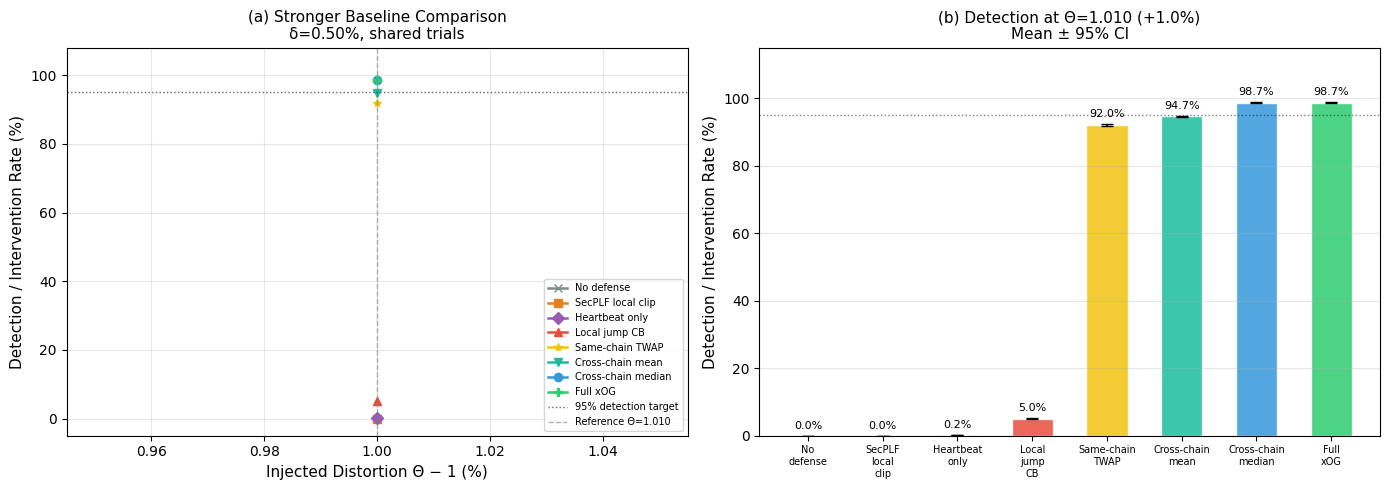

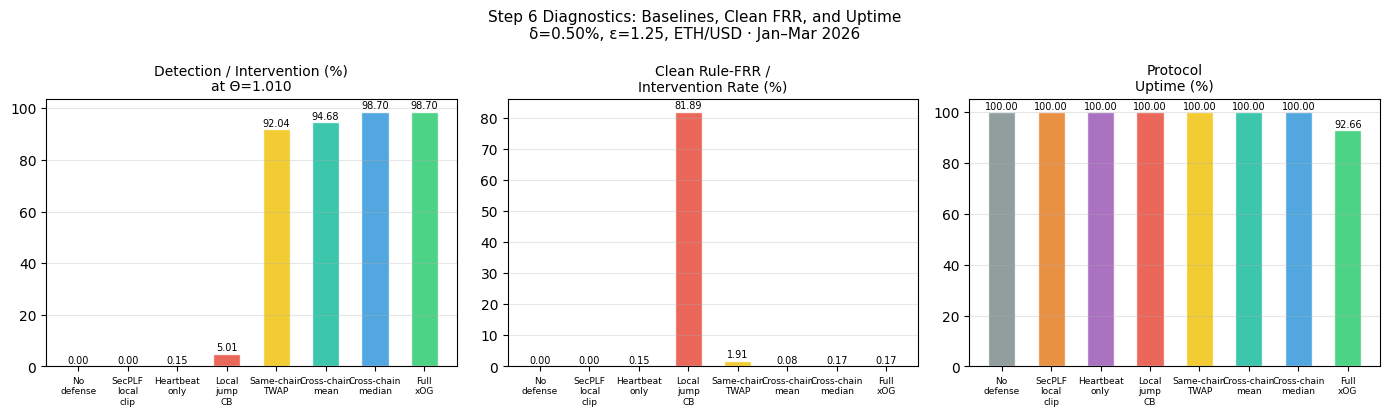

In [6]:
"""Step 6/6: with local twap Stronger baselines, component roles, scaling, and contamination stress.

This step reuses the shared attack trials generated in Step 4 and the xOCB
uptime output from Step 5. It strengthens the ablation by adding:

  - no-defense baseline;
  - SecPLF-style local clipping baseline;
  - stale-feed / heartbeat-only baseline;
  - local price-jump circuit breaker baseline;
  - same-chain trailing-TWAP baseline with w=5 minutes;
  - cross-chain mean consistency baseline;
  - cross-chain median consistency baseline;
  - full xOG baseline with median consistency, X2 clipping, and xOCB uptime;
  - k=3 leave-one-out scaling analysis;
  - contaminated-feed stress test.

Notes:
  - Detection is measured as rejection or protective intervention on the attack sample.
  - xOCB affects uptime, not the attack-sample detection probability.
  - The same-chain TWAP baseline uses only the target chain's own feed history.
  - The contamination stress test synthetically corrupts additional feeds using
    the same ramp profile as the original Step 4 attack trial.
"""

print("── Step 6: local twap Stronger Baselines, Ablation, Scaling, and Stress ───────")

if "step4" not in RESULTS or "shared_attack_trials" not in RESULTS["step4"]:
    raise RuntimeError("Step 6 requires Step 4 to run first because it reuses Step 4 shared attack trials.")
if "step5" not in RESULTS:
    raise RuntimeError("Step 6 requires Step 5 to run first because it reuses Step 5 xOCB uptime.")
if "step3" not in RESULTS:
    raise RuntimeError("Step 6 requires Step 3 to run first because it uses the profitability-margin summary.")

# ── Configuration ────────────────────────────────────────────────────────────

EPSILON = 1.25
THETA_VALUES = [1.010]
THETA_REF = 1.010

# Local jump threshold for the local price-jump circuit breaker.
# Using DELTA keeps this baseline comparable to the xTCP operating threshold.
try:
    LOCAL_JUMP_DELTA
except NameError:
    LOCAL_JUMP_DELTA = DELTA

# Same-chain trailing-TWAP baseline.
# Uses only the attacked/target chain's own feed history.
# Since the data are one-minute aligned, w=5 minutes corresponds to 5 samples.
try:
    LOCAL_TWAP_W_MINS
except NameError:
    LOCAL_TWAP_W_MINS = 5

try:
    LOCAL_TWAP_WINDOW_STEPS
except NameError:
    LOCAL_TWAP_WINDOW_STEPS = int(LOCAL_TWAP_W_MINS)

try:
    LOCAL_TWAP_DELTA
except NameError:
    LOCAL_TWAP_DELTA = DELTA

# Heartbeat-only baseline. This is intentionally simple: it rejects only if the
# local feed has remained unchanged longer than this stale-window threshold.
try:
    HEARTBEAT_MAX_MINS
except NameError:
    HEARTBEAT_MAX_MINS = 60

# Action-specific X2 clipping factors used for the experimental rule.
# These are intentionally wider than the 1% sensitivity-boundary attacks, so X2
# should not dominate detection at Θ=1.010.
try:
    LAMBDA_DOWN
except NameError:
    LAMBDA_DOWN = 1 / EPSILON

try:
    LAMBDA_UP
except NameError:
    LAMBDA_UP = EPSILON

CONFIGS = [
    "No defense",
    "SecPLF local clip",
    "Heartbeat only",
    "Local jump CB",
    "Same-chain TWAP",
    "Cross-chain mean",
    "Cross-chain median",
    "Full xOG",
]

CONFIG_REFERENCE = {
    "No defense": "None",
    "SecPLF local clip": "Previous local accepted price",
    "Heartbeat only": "Feed freshness",
    "Local jump CB": "Previous local accepted price",
    "Same-chain TWAP": f"Local {LOCAL_TWAP_W_MINS}-min trailing TWAP",
    "Cross-chain mean": "Mean of monitored feeds",
    "Cross-chain median": "Median of monitored feeds",
    "Full xOG": "Median + X2 + xOCB",
}

THETA_BOUNDARY = RESULTS["step4"]["theta_boundary"]
SHARED_ATTACK_TRIALS = RESULTS["step4"]["shared_attack_trials"]
theta_key = RESULTS["step4"]["theta_key"]

missing = [theta for theta in THETA_VALUES if theta_key(theta) not in SHARED_ATTACK_TRIALS[0]]
if missing:
    raise ValueError(f"Step 4 shared trials do not contain Step 6 theta values: {missing}")

print(
    f"Reusing Step 4 shared trials: {N_RUNS} runs × {N_ATTACKS} attacks × "
    f"{len(THETA_VALUES)} theta values × {RAMP_STEPS} ramp steps"
)

print(
    f"Same-chain TWAP baseline: w={LOCAL_TWAP_W_MINS} min "
    f"({LOCAL_TWAP_WINDOW_STEPS} one-minute samples), "
    f"τ_TWAP={LOCAL_TWAP_DELTA*100:.2f}%"
)

# ── Helper functions ─────────────────────────────────────────────────────────

def ref_price(noisy, chains, ref_type="median"):
    vals = np.array([noisy[c] for c in chains], dtype=float)
    if ref_type == "median":
        return float(np.median(vals))
    if ref_type == "mean":
        return float(np.mean(vals))
    raise ValueError(f"Unknown ref_type: {ref_type}")


def xchain_reject(noisy, chain, delta, chains=None, ref_type="median"):
    if chains is None:
        chains = CHAINS
    r = ref_price(noisy, chains, ref_type=ref_type)
    if r <= 0:
        return True
    return abs(noisy[chain] - r) / r > delta


def secplf_local_clip(candidate_price, last_accepted, epsilon):
    """SecPLF-style one-sided upper clipping. Returns effective price and clipped flag."""
    if last_accepted is None or last_accepted <= 0:
        return candidate_price, False
    upper = epsilon * last_accepted
    effective = min(candidate_price, upper)
    return effective, candidate_price > upper


def local_jump_reject(candidate_price, last_accepted, jump_delta):
    """Bidirectional local price-jump circuit breaker."""
    if last_accepted is None or last_accepted <= 0:
        return False
    return abs(candidate_price / last_accepted - 1.0) > jump_delta


def x2_intersection_or_clip(noisy, chain, last_accepted, delta, lambda_down, lambda_up, chains=None):
    """Full X2 interval-intersection logic used by xOG.

    Returns:
      accepted_price, intervened

    intervened=True means either the X2 interval was incompatible or the local
    price had to be clipped. This is counted as protective intervention.
    """
    if chains is None:
        chains = CHAINS

    candidate = noisy[chain]

    if last_accepted is None or last_accepted <= 0:
        # No prior anchor; accept the X1-passing candidate without X2 clipping.
        return candidate, False

    med = ref_price(noisy, chains, ref_type="median")
    lower = max((1 - delta) * med, lambda_down * last_accepted)
    upper = min((1 + delta) * med, lambda_up * last_accepted)

    if lower > upper:
        # X1 median interval and local clipping interval are incompatible.
        return last_accepted, True

    effective = min(max(candidate, lower), upper)
    clipped = abs(effective - candidate) > 1e-12
    return effective, clipped


def get_trial_start_iloc(trial):
    """Best-effort extraction of the row position used by a Step 4 trial."""
    int_keys = ["row_pos", "row_idx", "idx", "t_idx", "timestamp_idx", "df_idx", "sample_idx"]
    for key in int_keys:
        if key in trial:
            val = trial[key]
            if isinstance(val, (int, np.integer)):
                return int(val)

    time_keys = ["timestamp", "time", "datetime", "date"]
    for key in time_keys:
        if key in trial:
            val = trial[key]
            try:
                loc = df.index.get_loc(val)
                if isinstance(loc, (int, np.integer)):
                    return int(loc)
            except Exception:
                pass

    return None


def init_local_twap_history(trial, chain, window_steps=LOCAL_TWAP_WINDOW_STEPS):
    """Initialize local TWAP history from the target chain's own clean historical feed.

    The history uses only observations strictly before the attack trial start.
    If row-position metadata is unavailable, it falls back to prev_clean_price.
    """
    start_iloc = get_trial_start_iloc(trial)
    history = []

    if start_iloc is not None:
        lo = max(0, start_iloc - window_steps)
        hi = max(0, start_iloc)
        vals = df[chain].iloc[lo:hi].dropna().astype(float).tolist()
        history.extend(vals[-window_steps:])

    if not history:
        prev = trial.get("prev_clean_price", None)
        if prev is not None and prev > 0:
            history.append(float(prev))

    return history[-window_steps:]


def local_twap_reference(history):
    """Return the trailing local TWAP reference from prior local history."""
    if history is None or len(history) == 0:
        return None

    arr = np.asarray(history, dtype=float)
    arr = arr[np.isfinite(arr)]

    if len(arr) == 0:
        return None

    ref = float(np.mean(arr))
    return ref if ref > 0 else None


def local_twap_reject(candidate_price, history, twap_delta=LOCAL_TWAP_DELTA):
    """Same-chain trailing-TWAP filter.

    Rejects if the candidate deviates from the target chain's own trailing TWAP.
    This baseline does not observe cross-chain prices.
    """
    ref = local_twap_reference(history)
    if ref is None:
        return False
    return abs(candidate_price - ref) / ref > twap_delta


def append_local_twap_history(history, candidate_price, window_steps=LOCAL_TWAP_WINDOW_STEPS):
    """Append observed local feed price to the same-chain TWAP history."""
    if history is None:
        history = []

    if candidate_price is not None and np.isfinite(candidate_price):
        history.append(float(candidate_price))

    return history[-window_steps:]


# ── Precompute stale-window diagnostics for heartbeat-only baseline ──────────

stale_minutes_by_chain = {}
for c in CHAINS:
    changed = df[c].diff().abs().fillna(np.inf) > 0
    run = 0
    stale_arr = np.zeros(len(df), dtype=int)

    for i, is_changed in enumerate(changed):
        run = 0 if is_changed else run + 1
        stale_arr[i] = run

    stale_minutes_by_chain[c] = stale_arr


def heartbeat_reject_trial(trial, step_idx, chain):
    """Heartbeat-only rejection for a trial step, if the trial carries row index metadata."""
    start_iloc = get_trial_start_iloc(trial)
    if start_iloc is None:
        return False

    iloc = min(start_iloc + step_idx, len(df) - 1)
    return stale_minutes_by_chain[chain][iloc] > HEARTBEAT_MAX_MINS


# ── Attack-trial evaluation for stronger baselines ───────────────────────────

def evaluate_attack_trial(config, trial, theta=None, chains=None):
    if chains is None:
        chains = CHAINS

    attacked_chain = trial["attacked_chain"]
    if attacked_chain not in chains:
        return None

    if config == "No defense":
        return False

    last_accepted = trial.get("prev_clean_price", None)

    local_twap_history = None
    if config == "Same-chain TWAP":
        local_twap_history = init_local_twap_history(
            trial,
            attacked_chain,
            window_steps=LOCAL_TWAP_WINDOW_STEPS,
        )

    for step_idx, payload in enumerate(trial["step_payloads"]):
        noisy = payload["noisy"]
        candidate_local_price = noisy[attacked_chain]

        if config == "SecPLF local clip":
            effective, clipped = secplf_local_clip(candidate_local_price, last_accepted, EPSILON)
            if clipped:
                return True
            last_accepted = effective
            continue

        if config == "Heartbeat only":
            if heartbeat_reject_trial(trial, step_idx, attacked_chain):
                return True
            last_accepted = candidate_local_price
            continue

        if config == "Local jump CB":
            if local_jump_reject(candidate_local_price, last_accepted, LOCAL_JUMP_DELTA):
                return True
            last_accepted = candidate_local_price
            continue

        if config == "Same-chain TWAP":
            if local_twap_reject(candidate_local_price, local_twap_history, LOCAL_TWAP_DELTA):
                return True

            # If not rejected, the local feed observation becomes part of the
            # future same-chain TWAP history. This makes gradual/ramp attacks
            # harder for the local-only baseline, which is realistic.
            local_twap_history = append_local_twap_history(
                local_twap_history,
                candidate_local_price,
                window_steps=LOCAL_TWAP_WINDOW_STEPS,
            )
            last_accepted = candidate_local_price
            continue

        if config == "Cross-chain mean":
            if xchain_reject(noisy, attacked_chain, DELTA, chains=chains, ref_type="mean"):
                return True
            last_accepted = candidate_local_price
            continue

        if config == "Cross-chain median":
            if xchain_reject(noisy, attacked_chain, DELTA, chains=chains, ref_type="median"):
                return True
            last_accepted = candidate_local_price
            continue

        if config == "Full xOG":
            # X1 median-consistency rejection.
            if xchain_reject(noisy, attacked_chain, DELTA, chains=chains, ref_type="median"):
                return True

            # X2 action-specific local clipping/intersection intervention.
            effective, intervened = x2_intersection_or_clip(
                noisy,
                attacked_chain,
                last_accepted,
                DELTA,
                LAMBDA_DOWN,
                LAMBDA_UP,
                chains=chains,
            )
            if intervened:
                return True
            last_accepted = effective
            continue

        raise ValueError(f"Unknown config: {config}")

    return False


# ── Detection evaluation using the exact same Step 4 trials ──────────────────

det_runs = np.zeros((N_RUNS, len(CONFIGS), len(THETA_VALUES)))

for run in range(N_RUNS):
    for ci, config in enumerate(CONFIGS):
        for ti, theta in enumerate(THETA_VALUES):
            key = theta_key(theta)
            vals = []

            for trial in SHARED_ATTACK_TRIALS[run][key]:
                detected = evaluate_attack_trial(config, trial, theta=theta, chains=CHAINS)
                if detected is not None:
                    vals.append(bool(detected))

            det_runs[run, ci, ti] = np.mean(vals) * 100 if vals else np.nan

det_mean = np.nanmean(det_runs, axis=0)
det_ci = 1.96 * np.nanstd(det_runs, axis=0, ddof=1) / np.sqrt(np.sum(~np.isnan(det_runs), axis=0))

print("\nDetection/intervention rate by configuration:")
header = f"{'Config':<26} | " + " | ".join(f"Θ={t:.3f}" for t in THETA_VALUES)
print(header)
print("-" * len(header))

for ci, config in enumerate(CONFIGS):
    cells = [f"{det_mean[ci, ti]:>5.1f}±{det_ci[ci, ti]:.1f}%" for ti in range(len(THETA_VALUES))]
    print(f"{config:<26} | " + " | ".join(cells))

theta_ref_idx = THETA_VALUES.index(THETA_REF)


# ── Clean rule-FRR / rule-intervention diagnostic ────────────────────────────

clean_rng = np.random.default_rng(SEED + 1000)
clean_noisy_rows = []

for _, row in df.iterrows():
    base = {c: row[c] for c in CHAINS}
    clean_noisy_rows.append(build_injected_prices(base))


def clean_rule_frr(config):
    last_accepted = {c: None for c in CHAINS}
    local_twap_histories = {c: [] for c in CHAINS}

    rejected = 0
    total = 0

    for row_pos, noisy in enumerate(clean_noisy_rows):
        for c in CHAINS:
            total += 1
            candidate = noisy[c]

            if config == "No defense":
                last_accepted[c] = candidate
                continue

            if config == "SecPLF local clip":
                effective, clipped = secplf_local_clip(candidate, last_accepted[c], EPSILON)
                if clipped:
                    rejected += 1
                    # Keep effective accepted price.
                last_accepted[c] = effective
                continue

            if config == "Heartbeat only":
                if stale_minutes_by_chain[c][row_pos] > HEARTBEAT_MAX_MINS:
                    rejected += 1
                    continue
                last_accepted[c] = candidate
                continue

            if config == "Local jump CB":
                if local_jump_reject(candidate, last_accepted[c], LOCAL_JUMP_DELTA):
                    rejected += 1
                    continue
                last_accepted[c] = candidate
                continue

            if config == "Same-chain TWAP":
                if local_twap_reject(candidate, local_twap_histories[c], LOCAL_TWAP_DELTA):
                    rejected += 1

                # The baseline is a same-chain feed-history filter. The observed
                # local feed value is included in future TWAP history, because
                # TWAP is computed from the feed history rather than from the
                # protocol's cross-chain accepted-price state.
                local_twap_histories[c] = append_local_twap_history(
                    local_twap_histories[c],
                    candidate,
                    window_steps=LOCAL_TWAP_WINDOW_STEPS,
                )
                last_accepted[c] = candidate
                continue

            if config == "Cross-chain mean":
                if xchain_reject(noisy, c, DELTA, chains=CHAINS, ref_type="mean"):
                    rejected += 1
                    continue
                last_accepted[c] = candidate
                continue

            if config == "Cross-chain median":
                if xchain_reject(noisy, c, DELTA, chains=CHAINS, ref_type="median"):
                    rejected += 1
                    continue
                last_accepted[c] = candidate
                continue

            if config == "Full xOG":
                if xchain_reject(noisy, c, DELTA, chains=CHAINS, ref_type="median"):
                    rejected += 1
                    continue

                effective, intervened = x2_intersection_or_clip(
                    noisy,
                    c,
                    last_accepted[c],
                    DELTA,
                    LAMBDA_DOWN,
                    LAMBDA_UP,
                    chains=CHAINS,
                )

                if intervened:
                    rejected += 1
                    # Keep effective if clipping occurred; if interval was incompatible,
                    # effective equals last accepted and the update is rejected.
                else:
                    last_accepted[c] = effective
                continue

            raise ValueError(f"Unknown config: {config}")

    return rejected / total * 100 if total else np.nan


frr_results = {config: clean_rule_frr(config) for config in CONFIGS}

uptime_xog = RESULTS["step5"]["selected"]["uptime_pct"]
uptime_results = {config: 100.0 for config in CONFIGS}
uptime_results["Full xOG"] = uptime_xog

baseline_rows = []

for ci, config in enumerate(CONFIGS):
    baseline_rows.append({
        "configuration": config,
        "reference": CONFIG_REFERENCE[config],
        "theta": THETA_REF,
        "detection_pct": float(det_mean[ci, theta_ref_idx]),
        "ci95_pct": float(det_ci[ci, theta_ref_idx]),
        "clean_rule_frr_pct": float(frr_results[config]),
        "uptime_pct": float(uptime_results[config]),
    })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(OUTPUT_DIR / "step6_baseline_comparison.csv", index=False)

print(f"\nBaseline comparison at Θ={THETA_REF:.3f}:")
print(
    baseline_df[[
        "configuration",
        "reference",
        "detection_pct",
        "ci95_pct",
        "clean_rule_frr_pct",
        "uptime_pct",
    ]].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)
print("Saved: step6_baseline_comparison.csv")


# ── Scaling and contaminated-feed stress ─────────────────────────────────────

def corrupt_additional_feeds(noisy, attacked_chain, chains, theta, step_idx, n_steps, n_corrupt):
    """Create a noisy price vector with n_corrupt feeds distorted.

    The original Step 4 trial already distorts attacked_chain. This function
    distorts additional chains using the same linear ramp factor.
    """
    noisy2 = dict(noisy)
    ordered = list(chains)

    if attacked_chain not in ordered:
        return noisy2, []

    start = ordered.index(attacked_chain)
    corrupt_chains = [attacked_chain]

    offset = 1
    while len(corrupt_chains) < n_corrupt and offset < len(ordered) + 1:
        c = ordered[(start + offset) % len(ordered)]
        if c not in corrupt_chains:
            corrupt_chains.append(c)
        offset += 1

    step_factor = 1.0 + (theta - 1.0) * ((step_idx + 1) / max(n_steps, 1))

    for c in corrupt_chains:
        if c != attacked_chain:
            noisy2[c] = noisy2[c] * step_factor

    return noisy2, corrupt_chains


def evaluate_contamination_trial(trial, theta, chains, n_corrupt, ref_type="median"):
    attacked_chain = trial["attacked_chain"]
    if attacked_chain not in chains:
        return None
    if n_corrupt > len(chains):
        return None

    step_payloads = trial["step_payloads"]
    n_steps = len(step_payloads)

    for step_idx, payload in enumerate(step_payloads):
        noisy_mod, corrupt_chains = corrupt_additional_feeds(
            payload["noisy"],
            attacked_chain,
            chains,
            theta,
            step_idx,
            n_steps,
            n_corrupt,
        )

        # Attack is detected if any corrupted feed is rejected by the consistency rule.
        for c in corrupt_chains:
            if c in chains and xchain_reject(noisy_mod, c, DELTA, chains=chains, ref_type=ref_type):
                return True

    return False


def run_stress_setting(setting_name, chains, n_corrupt, ref_type="median", theta=THETA_REF):
    key = theta_key(theta)
    run_rates = []

    for run in range(N_RUNS):
        vals = []

        for trial in SHARED_ATTACK_TRIALS[run][key]:
            detected = evaluate_contamination_trial(
                trial,
                theta=theta,
                chains=chains,
                n_corrupt=n_corrupt,
                ref_type=ref_type,
            )

            if detected is not None:
                vals.append(bool(detected))

        if vals:
            run_rates.append(np.mean(vals) * 100)

    if len(run_rates) == 0:
        return {
            "setting": setting_name,
            "chains": ",".join(chains),
            "k": len(chains),
            "corrupted_feeds": n_corrupt,
            "reference": ref_type,
            "detection_pct": np.nan,
            "ci95_pct": np.nan,
            "n_runs_used": 0,
        }

    run_rates = np.array(run_rates, dtype=float)

    return {
        "setting": setting_name,
        "chains": ",".join(chains),
        "k": len(chains),
        "corrupted_feeds": n_corrupt,
        "reference": ref_type,
        "detection_pct": float(run_rates.mean()),
        "ci95_pct": (
            float(1.96 * run_rates.std(ddof=1) / np.sqrt(len(run_rates)))
            if len(run_rates) > 1 else 0.0
        ),
        "n_runs_used": int(len(run_rates)),
    }


stress_rows = []

# k=3 leave-one-out scaling.
for dropped in CHAINS:
    subset = [c for c in CHAINS if c != dropped]
    stress_rows.append(run_stress_setting(
        setting_name=f"k=3 leave-one-out; drop {dropped}",
        chains=subset,
        n_corrupt=1,
        ref_type="median",
        theta=THETA_REF,
    ))

# k=4 mean-vs-median comparison.
stress_rows.append(run_stress_setting(
    setting_name="k=4 all chains",
    chains=CHAINS,
    n_corrupt=1,
    ref_type="mean",
    theta=THETA_REF,
))
stress_rows.append(run_stress_setting(
    setting_name="k=4 all chains",
    chains=CHAINS,
    n_corrupt=1,
    ref_type="median",
    theta=THETA_REF,
))

# Contaminated-feed stress. For k=4, f=1 is within f<k/2; f>=2 violates the
# strict median-robustness assumption and is intentionally reported as stress.
for n_corrupt in [2, 3]:
    stress_rows.append(run_stress_setting(
        setting_name="k=4 contaminated-feed stress",
        chains=CHAINS,
        n_corrupt=n_corrupt,
        ref_type="median",
        theta=THETA_REF,
    ))

stress_df = pd.DataFrame(stress_rows)
stress_df.to_csv(OUTPUT_DIR / "step6_scaling_contamination_stress.csv", index=False)

print(f"\nScaling and contamination stress at Θ={THETA_REF:.3f}:")
print(
    stress_df[[
        "setting",
        "k",
        "corrupted_feeds",
        "reference",
        "detection_pct",
        "ci95_pct",
        "n_runs_used",
    ]].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)
print("Saved: step6_scaling_contamination_stress.csv")


# ── Figures ──────────────────────────────────────────────────────────────────

theta_pcts = [(t - 1.0) * 100.0 for t in THETA_VALUES]

colors = [
    "#7f8c8d",  # No defense
    "#e67e22",  # SecPLF local clip
    "#9b59b6",  # Heartbeat only
    "#e74c3c",  # Local jump CB
    "#f1c40f",  # Same-chain TWAP
    "#1abc9c",  # Cross-chain mean
    "#3498db",  # Cross-chain median
    "#2ecc71",  # Full xOG
]

markers = ["x", "s", "D", "^", "*", "v", "o", "P"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for ci, (config, color, marker) in enumerate(zip(CONFIGS, colors, markers)):
    means = det_mean[ci]
    cis = det_ci[ci]
    ax.plot(theta_pcts, means, f"{marker}-", color=color, lw=1.8, markersize=6, label=config)
    ax.fill_between(
        theta_pcts,
        np.clip(means - cis, 0, 100),
        np.clip(means + cis, 0, 100),
        alpha=0.08,
        color=color,
    )

ax.axhline(95, color="black", lw=1, linestyle=":", alpha=0.6, label="95% detection target")
ax.axvline((THETA_REF - 1.0) * 100.0, color="gray", lw=1, linestyle="--", alpha=0.6, label=f"Reference Θ={THETA_REF:.3f}")
ax.set_xlabel("Injected Distortion Θ − 1 (%)", fontsize=11)
ax.set_ylabel("Detection / Intervention Rate (%)", fontsize=11)
ax.set_title(f"(a) Stronger Baseline Comparison\nδ={DELTA*100:.2f}%, shared trials", fontsize=11)
ax.legend(fontsize=7, loc="lower right")
ax.grid(True, alpha=0.3)
ax.set_ylim(-5, 108)

ax2 = axes[1]
x = np.arange(len(CONFIGS))
means = [det_mean[ci, theta_ref_idx] for ci in range(len(CONFIGS))]
cis = [det_ci[ci, theta_ref_idx] for ci in range(len(CONFIGS))]
bars = ax2.bar(x, means, 0.55, color=colors, alpha=0.85, edgecolor="white")
ax2.errorbar(x, means, yerr=cis, fmt="none", color="black", capsize=4, lw=1.2)

for bar, mean, ci_v in zip(bars, means, cis):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        mean + ci_v + 1.5,
        f"{mean:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
    )

ax2.axhline(95, color="black", lw=1, linestyle=":", alpha=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels([c.replace(" ", "\n") for c in CONFIGS], fontsize=7)
ax2.set_ylabel("Detection / Intervention Rate (%)", fontsize=11)
ax2.set_title(f"(b) Detection at Θ={THETA_REF:.3f} (+{(THETA_REF - 1.0) * 100:.1f}%)\nMean ± 95% CI", fontsize=11)
ax2.grid(True, alpha=0.3, axis="y")
ax2.set_ylim(0, 115)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step6_baseline_comparison.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step6_baseline_comparison.png", bbox_inches="tight", dpi=150)
print("Saved: step6_baseline_comparison.pdf / .png")

fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.2))

metrics = {
    f"Detection / Intervention (%)\nat Θ={THETA_REF:.3f}": [det_mean[ci, theta_ref_idx] for ci in range(len(CONFIGS))],
    "Clean Rule-FRR /\nIntervention Rate (%)": [frr_results[c] for c in CONFIGS],
    "Protocol\nUptime (%)": [uptime_results[c] for c in CONFIGS],
}

for ax_i, (metric_label, values) in enumerate(metrics.items()):
    ax_m = axes2[ax_i]
    bars = ax_m.bar(range(len(CONFIGS)), values, color=colors, alpha=0.85, edgecolor="white", width=0.55)

    for bar, val in zip(bars, values):
        ax_m.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{val:.2f}",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax_m.set_xticks(range(len(CONFIGS)))
    ax_m.set_xticklabels([c.replace(" ", "\n") for c in CONFIGS], fontsize=6.5)
    ax_m.set_title(metric_label, fontsize=10)
    ax_m.grid(True, alpha=0.3, axis="y")

plt.suptitle(
    f"Step 6 Diagnostics: Baselines, Clean FRR, and Uptime\n"
    f"δ={DELTA*100:.2f}%, ε={EPSILON}, {ASSET_LABEL} · {PERIOD_LABEL}",
    fontsize=11,
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "step6_baseline_metrics.pdf", bbox_inches="tight")
plt.savefig(OUTPUT_DIR / "step6_baseline_metrics.png", bbox_inches="tight", dpi=150)
print("Saved: step6_baseline_metrics.pdf / .png")


# ── LaTeX tables ─────────────────────────────────────────────────────────────

def latex_config_label(config):
    return (
        config.replace("Full xOG", r"Full \xOG{}")
              .replace("SecPLF", r"SecPLF")
              .replace("xTCP", r"xTCP")
              .replace("Same-chain TWAP", r"Same-chain TWAP")
    )


print("\nLaTeX table: stronger baseline comparison")

lines = [
    r"\begin{table*}[t]",
    r"\centering",
    rf"\caption{{Baseline comparison at the xTCP sensitivity boundary ($\Theta={THETA_REF:.3f}$, $\delta={DELTA*100:.1f}\%$). All configurations use the same sampled attack timestamps, attacked chains, injected distortions, ramp steps, and historical feed values.}}",
    r"\label{tab:baseline_comparison}",
    r"\small",
    r"\begin{tabular}{@{}lccc p{5.3cm}@{}}",
    r"\toprule",
    r"\textbf{Configuration} & \textbf{Detect./intervene} & \textbf{Clean rule-FRR} & \textbf{Uptime} & \textbf{Interpretation} \\",
    r"\midrule",
]

interpretations = {
    "No defense": "No rejection or price-bounding rule is applied.",
    "SecPLF local clip": "Bounds large one-sided local jumps but does not compare chains.",
    "Heartbeat only": "Rejects stale feeds but not fresh cross-chain-inconsistent prices.",
    "Local jump CB": "Detects abrupt local movement but can miss slow or spatially inconsistent drift.",
    "Same-chain TWAP": "Uses only the target chain's trailing feed history; smooths local movement but does not compare chains.",
    "Cross-chain mean": "Uses spatial aggregation, but the reference is pulled toward outliers.",
    "Cross-chain median": "Robust spatial consistency check without xOCB response.",
    "Full xOG": "Combines median consistency, action-specific clipping, and xOCB response.",
}

for _, row in baseline_df.iterrows():
    label = latex_config_label(row["configuration"])
    det = row["detection_pct"]
    ci_v = row["ci95_pct"]
    frr = row["clean_rule_frr_pct"]
    uptime = row["uptime_pct"]
    interp = interpretations[row["configuration"]]

    lines.append(
        f"{label} & ${det:.1f}\\pm{ci_v:.1f}$\\% & {frr:.2f}\\% & {uptime:.2f}\\% & {interp} " + r"\\"
    )

lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
print_latex(lines)


print("\nLaTeX table: scaling and contamination stress")

lines = [
    r"\begin{table}[t]",
    r"\centering",
    rf"\caption{{Chain-count and contamination stress at $\Theta={THETA_REF:.3f}$ and $\delta={DELTA*100:.1f}\%$. For $k=4$, one corrupted feed is within the strict median-robustness assumption $f<k/2$; two or more corrupted feeds violate it and are reported as stress cases.}}",
    r"\label{tab:scaling_stress}",
    r"\small",
    r"\begin{tabular}{@{}lccc@{}}",
    r"\toprule",
    r"\textbf{Setting} & $\boldsymbol{k}$ & \textbf{Corrupt feeds} & \textbf{Detect.} \\",
    r"\midrule",
]

for _, row in stress_df.iterrows():
    setting = row["setting"]

    if "leave-one-out" in setting:
        setting_label = setting.replace("k=3 leave-one-out; ", "LOO: ")
    elif row["reference"] == "mean":
        setting_label = r"$k=4$ mean"
    elif row["corrupted_feeds"] == 1:
        setting_label = r"$k=4$ median"
    else:
        setting_label = r"$k=4$ median stress"

    det = row["detection_pct"]
    ci_v = row["ci95_pct"]

    lines.append(
        f"{setting_label} & {int(row['k'])} & {int(row['corrupted_feeds'])} & ${det:.1f}\\pm{ci_v:.1f}$\\% " + r"\\"
    )

lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
print_latex(lines)


# ── Offline xTCP detection-delay diagnostic ────────────────────────────────
# Measures the first one-minute ramp step at which xTCP rejects an injected
# distortion. This is an offline simulation diagnostic. It does NOT include
# production relayer delay, chain finality, or target-chain transaction inclusion.

print("\n── Offline xTCP Detection-Delay Diagnostic ───────────────────────")
print("Measured as first rejected ramp step under the one-minute sampled ramp model.")

def xtcp_median_reject(noisy, chain, delta, chains=None):
    if chains is None:
        chains = CHAINS

    vals = np.array([noisy[c] for c in chains], dtype=float)
    med = float(np.median(vals))

    if med <= 0:
        return True

    return abs(noisy[chain] - med) / med > delta


def first_xtcp_detection_step(trial, delta=DELTA, chains=None):
    if chains is None:
        chains = CHAINS

    attacked_chain = trial["attacked_chain"]

    if attacked_chain not in chains:
        return np.nan

    for step_idx, payload in enumerate(trial["step_payloads"], start=1):
        noisy = payload["noisy"]
        if xtcp_median_reject(noisy, attacked_chain, delta, chains=chains):
            return step_idx

    return np.nan


delay_rows = []

for theta in THETA_VALUES:
    key = theta_key(theta)

    run_detection_rates = []
    all_detect_steps = []

    for run in range(N_RUNS):
        run_steps = []

        for trial in SHARED_ATTACK_TRIALS[run][key]:
            step = first_xtcp_detection_step(trial, delta=DELTA, chains=CHAINS)

            if not np.isnan(step):
                run_steps.append(step)
                all_detect_steps.append(step)

        run_detection_rates.append(len(run_steps) / N_ATTACKS * 100.0)

    detection_mean = float(np.mean(run_detection_rates))
    detection_ci = float(
        1.96 * np.std(run_detection_rates, ddof=1) / np.sqrt(len(run_detection_rates))
    )

    if len(all_detect_steps) > 0:
        mean_step = float(np.mean(all_detect_steps))
        median_step = float(np.median(all_detect_steps))
        p95_step = float(np.percentile(all_detect_steps, 95))
        max_step = float(np.max(all_detect_steps))
    else:
        mean_step = np.nan
        median_step = np.nan
        p95_step = np.nan
        max_step = np.nan

    delay_rows.append({
        "theta": theta,
        "distortion_pct": (theta - 1.0) * 100.0,
        "detection_pct": detection_mean,
        "detection_ci95_pct": detection_ci,
        "mean_first_detect_step": mean_step,
        "median_first_detect_step": median_step,
        "p95_first_detect_step": p95_step,
        "max_first_detect_step": max_step,
        "mean_detection_minutes_offline": mean_step,
        "median_detection_minutes_offline": median_step,
        "p95_detection_minutes_offline": p95_step,
    })

delay_df = pd.DataFrame(delay_rows)

try:
    delay_path = OUTPUT_DIR / "step6_xtcp_detection_delay.csv"
except NameError:
    delay_path = "step6_xtcp_detection_delay.csv"

delay_df.to_csv(delay_path, index=False)

print(delay_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"Saved: {delay_path}")


print("\nLaTeX table: offline xTCP detection delay")

lines = [
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Offline xTCP detection delay under one-minute ramp-attack sampling. Delay is measured as the first ramp step at which xTCP rejects the injected distortion and excludes production relayer, finality, and target-chain inclusion latency.}",
    r"\label{tab:xtcp_detection_delay}",
    r"\small",
    r"\begin{tabular}{@{}lcccc@{}}",
    r"\toprule",
    r"\textbf{$\Theta$} & \textbf{Distort.} & \textbf{Detect.} & \textbf{Median step} & \textbf{P95 step} \\",
    r"\midrule",
]

for _, row in delay_df.iterrows():
    theta = row["theta"]
    distort = row["distortion_pct"]
    detect = row["detection_pct"]
    ci = row["detection_ci95_pct"]
    med_step = row["median_first_detect_step"]
    p95_step = row["p95_first_detect_step"]

    med_str = "--" if np.isnan(med_step) else f"{med_step:.1f}"
    p95_str = "--" if np.isnan(p95_step) else f"{p95_step:.1f}"

    lines.append(
        f"{theta:.3f} & {distort:.2f}\\% & "
        f"${detect:.1f}\\pm{ci:.1f}$\\% & {med_str} & {p95_str} \\\\"
    )

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
]

try:
    print_latex(lines)
except NameError:
    print("\n".join(lines))


# ── Final machine-readable summary ───────────────────────────────────────────

summary = {
    "dataset_name": DATASET_NAME,
    "asset_label": ASSET_LABEL,
    "period_label": PERIOD_LABEL,
    "rows": int(len(df)),
    "p99_dev_pct": float(P99_NATURAL_PCT),
    "max_dev_pct": float(MAX_NATURAL_DEV_PCT),
    "theta_obs_max": float(RESULTS["step3"]["theta_obs_max"]),
    "min_profit_injection_pct": float(MIN_PROFIT_INJECTION_PCT),
    "boundary_theta": float(RESULTS["step4"]["boundary_theta"]),
    "boundary_detection_pct": float(RESULTS["step4"]["det_mean"][RESULTS["step4"]["boundary_idx"]]),
    "selected_delta_pct": float(DELTA * 100),
    "frr_at_delta_pct": float(RESULTS["step4"]["frr_rates"][DELTA]),

    # xOCB summary. Keep old bacb keys for backward compatibility and add xocb aliases.
    "bacb_activations": int(RESULTS["step5"]["selected"]["activations"]),
    "bacb_rate_pct": float(RESULTS["step5"]["selected"]["rate_pct"]),
    "bacb_effective_susp_hours": float(RESULTS["step5"]["selected"]["effective_susp_hours"]),
    "bacb_uptime_pct": float(RESULTS["step5"]["selected"]["uptime_pct"]),
    "xocb_activations": int(RESULTS["step5"]["selected"]["activations"]),
    "xocb_rate_pct": float(RESULTS["step5"]["selected"]["rate_pct"]),
    "xocb_effective_susp_hours": float(RESULTS["step5"]["selected"]["effective_susp_hours"]),
    "xocb_uptime_pct": float(RESULTS["step5"]["selected"]["uptime_pct"]),

    # Step 6 detection metrics.
    "step6_full_xog_detection_pct": float(det_mean[CONFIGS.index("Full xOG"), theta_ref_idx]),
    "step6_full_xog_ci_pct": float(det_ci[CONFIGS.index("Full xOG"), theta_ref_idx]),
    "step6_cross_chain_median_detection_pct": float(det_mean[CONFIGS.index("Cross-chain median"), theta_ref_idx]),
    "step6_cross_chain_mean_detection_pct": float(det_mean[CONFIGS.index("Cross-chain mean"), theta_ref_idx]),
    "step6_same_chain_twap_detection_pct": float(det_mean[CONFIGS.index("Same-chain TWAP"), theta_ref_idx]),
    "step6_same_chain_twap_ci_pct": float(det_ci[CONFIGS.index("Same-chain TWAP"), theta_ref_idx]),
    "step6_same_chain_twap_frr_pct": float(frr_results["Same-chain TWAP"]),
    "local_twap_w_mins": int(LOCAL_TWAP_W_MINS),
    "local_twap_delta_pct": float(LOCAL_TWAP_DELTA * 100),
}

Path("results_summary.json").write_text(json.dumps(summary, indent=2))
pd.DataFrame([summary]).to_csv("results_summary.csv", index=False)

RESULTS["step6"] = {
    "configs": CONFIGS,
    "theta_values": THETA_VALUES,
    "theta_ref": THETA_REF,
    "local_twap_w_mins": LOCAL_TWAP_W_MINS,
    "local_twap_delta": LOCAL_TWAP_DELTA,
    "det_runs": det_runs,
    "det_mean": det_mean,
    "det_ci": det_ci,
    "frr_results": frr_results,
    "uptime_results": uptime_results,
    "baseline_comparison": baseline_df,
    "scaling_contamination_stress": stress_df,
    "xtcp_detection_delay": delay_df,
}

print("\nSaved: results_summary.json / results_summary.csv")
print("Step 6 complete. local twap")